# Sparse Sensor Placement Optimization for Classification (`SSPOC`) on NYISO DART Spreads

**Project:** NYISO `N.Y.C.` (Zone J) Day-Ahead to Real-Time (DART) Spread Virtual Bidding (`2025–2026` Out-of-Sample)  
**Prerequisite Context:** While **Iterative & Scheduled-Refit `DMDc`** adapts to seasonal and fuel regime drift (`+$24.1k` Cum PnL, `3.12` Sharpe), it requires dense, full-state observations across all grid nodes and 424 exogenous variables, and its continuous linear MSE objective yields limited tail discrimination (`0.231` Tail F1).

### Objectives of This Notebook
Following **Brunton et al. (2016)** (*Sparse Sensor Placement Optimization for Classification*), we extract a minimal subset of $p \in \{5, 10, 20, 40\}$ critical generator buses out of **559 NYISO nodes** (projected onto a rank-25 POD basis capturing `98.0%` of nodal variance) and evaluate:

1. **Sensor Placement Ablation (`SSPOC` vs. `QR-Pivoting` vs. `Mutual-Info`):** Contrasts discriminative sparse sensing (`SSPOC`) against whole-grid reconstruction (`QR-Pivoting`) and univariate correlation (`Mutual-Info`) across 5 downstream classifiers (`Multinomial Logit`, `Logit`, `GBDT`, `LDA`, and `Balanced MLP`).
2. **Physical Transmission Bottleneck Interpretability:** Maps selected PTIDs to `P-19` generator and `P-23` subzone metadata to verify whether `SSPOC` discovers upstream congestion interfaces feeding `N.Y.C.`
3. **Spatial Generalization (`LONGIL` & `HUD VL`):** Tests whether `SSPOC` dynamically relocates its bellwether sensors to match the physical bottlenecks of adjacent load pockets.
4. **Expanding Walk-Forward Sensor Stability (`2025–2026`):** Measures quarterly Jaccard persistence across 8 out-of-sample cutoffs to identify invariant core grid sensors.
5. **Cross-Paradigm Head-to-Head (`30-Day Refit SSPOC` vs. `30-Day Refit DMDc`):** Evaluates `SSPOC` ($p=20$) under the exact same **30-day (`720h`) expanding-window refit schedule** used for `DMDc` to compare sparse nodal classification against dense forced dynamical modeling.


**Load** Cached Ablation Artifacts & P-19 / P-23 Metadata

In [44]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from data_loader import load_data
from sparse_sensor import run_sparse_sensor_ablation

# 1. Load cached dataset (hits Parquet cache immediately if already built)
data = load_data(force_refresh_active=False)

# 2. Run or load cached sparse sensor ablation for N.Y.C. (Zone J)
ablation = run_sparse_sensor_ablation(
    data=data,
    target_zone="N.Y.C.",
    p_budgets=(5, 10, 20, 40),
    pod_rank=25,
    sspoc_alpha_frac= 0.15,
    force_recompute=False,
)

metrics_df = ablation["metrics_df"]
recon_df = ablation["recon_df"]
sensors = ablation["selected_sensors"]
meta = ablation["meta"]

print(f"Total Generator Nodes: {meta['n_nodes_total']} | POD Rank-{meta['pod_rank']} Energy: {meta['pod_energy_captured']*100:.1f}%")
display(recon_df.pivot(index="p", columns="Scheme", values=["Grid R2", "Grid RMSE ($/MWh)"]))


P-54B (rt_actual_outages) [83/83 cached]: 100%|██████████| 83/83 [00:00<00:00, 1071.85zip/s]
P-511A (dam_limiting_constraints) [249/249 cached]: 100%|██████████| 249/249 [00:00<00:00, 5153.88zip/s]
P-27 (dam_bid_data) [474/474 cached]: 100%|██████████| 474/474 [00:00<00:00, 2751.97zip/s]


[CACHE HIT] Loading dam_lbmp_gen.parquet...
[CACHE HIT] Loading rt_int_lbmp_gen.parquet...
[CACHE HIT] Loading dam_lbmp_zone.parquet...
[CACHE HIT] Loading rt_int_lbmp_zone.parquet...
[CACHE HIT] Loading iso_load_forecast.parquet...
[CACHE HIT] Loading weather_forecast.parquet...
[CACHE HIT] Loading zonal_bid_load.parquet...
[CACHE HIT] Loading btm_solar_forecast.parquet...
[CACHE HIT] Loading rt_int_actual_load.parquet...
[CACHE HIT] Loading dam_sched_outages.parquet...
[CACHE HIT] Loading rt_actual_outages.parquet...
[CACHE HIT] Loading dam_limiting_constraints.parquet...
[CACHE HIT] Loading rt_fuel_mix.parquet...
[CACHE HIT] Loading interface_flows.parquet...
[CACHE HIT] Partitioned dataset ready at nyiso_data/merged_parquet/dam_bid_data/...
[CACHE HIT] Loading nodal_dart_spread.parquet & labels...
[CACHE HIT] Loading zonal_dart_spread.parquet & labels...
[CACHE HIT] Loading exogenous_features.parquet...

=== Pipeline Complete ===
Nodal DART Matrix:      (59958, 559) (Timestamps x G

Grid R2                     Grid RMSE ($/MWh)                   
Scheme Mutual-Info QR-Pivoting   SSPOC       Mutual-Info QR-Pivoting  SSPOC
p                                                                          
5           0.2896      0.0281  0.0464             36.11       42.95  43.11
10          0.2880      0.0954  0.0746             36.24       41.79  42.70
20          0.0612      0.4057  0.1364             40.47       34.72  42.05
40         -0.2293      0.9454  0.1957             50.77       11.14  40.57

In [45]:
metrics_df

,Scheme,p,Model,Macro F1,Tail F1,Trades,Trade Freq (%),Win Rate (%),Avg PnL/Trade ($),Cum PnL ($),Annual Sharpe,Max DD ($)
0,QR-Pivoting,5,Multinomial Logit,0.3708,0.3073,11253,69.0,53.1,1.65,18518.72,1.69,14881.28
1,QR-Pivoting,5,GBDT,0.4484,0.3079,6570,40.3,57.2,1.99,13099.13,1.22,23865.08
2,QR-Pivoting,5,LDA,0.4062,0.2236,3927,24.1,55.8,2.60,10191.41,0.96,19250.14
3,QR-Pivoting,5,Balanced MLP,0.4143,0.2853,7495,46.0,50.2,3.10,23240.11,2.15,12421.40
4,QR-Pivoting,5,Logit (tau=0.18),0.3816,0.3103,10880,66.7,53.5,1.39,15152.82,1.38,16423.34
5,QR-Pivoting,10,Multinomial Logit,0.3722,0.3076,11200,68.7,53.3,1.59,17838.03,1.62,16288.82
6,QR-Pivoting,10,GBDT,0.4490,0.3088,6634,40.7,57.6,2.36,15686.13,1.43,25262.63
7,QR-Pivoting,10,LDA,0.4071,0.2248,3928,24.1,55.9,2.78,10916.46,1.03,19124.20
8,QR-Pivoting,10,Balanced MLP,0.3936,0.2720,8246,50.6,48.9,-0.32,-2608.35,-0.24,27038.56
9,QR-Pivoting,10,Logit (tau=0.20),0.3940,0.3094,10132,62.1,53.6,1.77,17890.51,1.63,14913.24


**Join** Selected PTIDs with P-19 Generator & P-23 Subzone Metadata


In [46]:
gen_meta = data["gen_meta"].copy()
subzone_meta = data["subzone_meta"].copy()

print("P-19 Columns:", list(gen_meta.columns))
print("P-23 Columns:", list(subzone_meta.columns))

# 1. Auto-detect PTID column (or index) in P-19
if gen_meta.index.name and "ptid" in str(gen_meta.index.name).lower():
    gen_meta = gen_meta.reset_index()

ptid_col = next((c for c in gen_meta.columns if "ptid" in str(c).lower()), None)
name_col = next((c for c in gen_meta.columns if "name" in str(c).lower() and "zone" not in str(c).lower()), None)
zone_col = next((c for c in gen_meta.columns if str(c).lower().strip() in ("zone", "zone name", "load zone")), None)
subzone_col = next((c for c in gen_meta.columns if "subzone" in str(c).lower()), None)

if ptid_col is not None:
    gen_meta["PTID_str"] = gen_meta[ptid_col].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
else:
    # Fallback: extract PTID -> Name directly from P-2B parquet if P-19 schema differs
    p2b_sample = pd.read_parquet("./nyiso_data/merged_parquet/dam_lbmp_gen.parquet", columns=["PTID", "Name"]).drop_duplicates("PTID")
    p2b_sample["PTID_str"] = p2b_sample["PTID"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    gen_meta = p2b_sample.rename(columns={"Name": "Generator Name"})
    name_col = "Generator Name"

rename_map = {}
if name_col and name_col != "Generator Name":
    rename_map[name_col] = "Generator Name"
if zone_col and zone_col != "Zone Name":
    rename_map[zone_col] = "Zone Name"
if subzone_col and subzone_col != "Subzone":
    rename_map[subzone_col] = "Subzone"

gen_meta_unique = gen_meta.rename(columns=rename_map).drop_duplicates(subset=["PTID_str"]).copy()

# Merge P-23 Subzone metadata if Subzone is available
if "Subzone" in gen_meta_unique.columns:
    p23_sub_col = next((c for c in subzone_meta.columns if "subzone" in str(c).lower()), None)
    if p23_sub_col:
        sub_clean = subzone_meta.rename(columns={p23_sub_col: "Subzone"}).drop_duplicates(subset=["Subzone"])
        gen_meta_unique = gen_meta_unique.merge(sub_clean, on="Subzone", how="left", suffixes=("", "_p23"))

def build_sensor_table(scheme_name: str, top_k: int = 20) -> pd.DataFrame:
    ptids = sensors[scheme_name]["ranked_ptids"][:top_k]
    scores = sensors[scheme_name]["scores"][:top_k]
    df_sel = pd.DataFrame({
        "Rank": np.arange(1, len(ptids) + 1),
        "PTID_str": [str(p).replace(".0", "").strip() for p in ptids],
        "Selection_Score": np.round(scores, 5),
    })
    merged = df_sel.merge(gen_meta_unique, on="PTID_str", how="left")
    priority_cols = ["Rank", "PTID_str", "Generator Name", "Zone Name", "Subzone", "Selection_Score"]
    keep_cols = [c for c in priority_cols if c in merged.columns]
    return merged[keep_cols]

sspoc_top20 = build_sensor_table("SSPOC", top_k=20)
qr_top20 = build_sensor_table("QR-Pivoting", top_k=20)
mi_top20 = build_sensor_table("Mutual-Info", top_k=20)

print("\n=== Top 20 Bellwether Nodes Selected by SSPOC (Target: N.Y.C.) ===")
display(sspoc_top20)

print("\n=== Top 20 Nodes Selected by QR-Pivoting (Whole-Grid Reconstruction) ===")
display(qr_top20)


P-19 Columns: ['Generator Name', 'Generator PTID', 'Aggregation PTID', 'Subzone', 'Zone', 'Latitude', 'Longitude', 'Active']
P-23 Columns: ['Transmission Owner', 'Subzone', 'Zone']

=== Top 20 Bellwether Nodes Selected by SSPOC (Target: N.Y.C.) ===


,Rank,PTID_str,Generator Name,Zone Name,Subzone,Selection_Score
0,1,323705,HUNTINGTON_RES_REC,LONGIL,LIPA LONG ISLAND,0.64887
1,2,24207,NEG___GEN_MONROE,GENESE,NMPC GENESEE,0.33166
2,3,23744,NINE_MILE_2,CENTRL,NMPC CENTRAL,0.31196
3,4,23575,NINE_MILE_1,CENTRL,NMPC CENTRAL,0.25398
4,5,323601,HQ_GEN_IMPORT,H Q,HQNY,0.25092
5,6,323574,MAPLE_RIDGE_WT_1,MHK VL,NMPC MOHAWK VLY,0.24924
6,7,323611,MAPLE_RIDGE_WT_2,MHK VL,NMPC MOHAWK VLY,0.24920
7,8,323591,NPX_GEN_1385_PROXY,NPX,NENP,0.19642
8,9,23651,HQ_GEN_WHEEL,H Q,HQEX,0.19269
9,10,323758,CRICKET___VALLEY_CC3,HUD VL,CON ED HUDSON VLY,0.17039



=== Top 20 Nodes Selected by QR-Pivoting (Whole-Grid Reconstruction) ===


,Rank,PTID_str,Generator Name,Zone Name,Subzone,Selection_Score
0,1,323705,HUNTINGTON_RES_REC,LONGIL,LIPA LONG ISLAND,1.00000
1,2,323591,NPX_GEN_1385_PROXY,NPX,NENP,0.50000
2,3,323758,CRICKET___VALLEY_CC3,HUD VL,CON ED HUDSON VLY,0.33333
3,4,23983,CH_RES_BVR_FALLS,MHK VL,NMPC MOHAWK VLY,0.25000
4,5,23512,ARTHUR_KILL_2,N.Y.C.,CON ED NY CITY,0.20000
5,6,323617,CANDIGU_WT_PWR,CENTRL,NYSEG CENTRAL,0.16667
6,7,23641,MONGAUP___HYD,HUD VL,O&R HUDSON VLY,0.14286
7,8,23847,NEWTON___FALLS_HYD,MHK VL,NMPC MOHAWK VLY,0.12500
8,9,23659,INDIAN POINT_GT_2,MILLWD,CON ED MILLWOOD,0.11111
9,10,323621,DELAWARE___LFGE,MHK VL,NYSEG MOHAWK VLY,0.10000


**Analyze** Spatial Distribution & Bottleneck Concentration

In [47]:
def summarize_zone_allocation(top_k: int = 20) -> pd.DataFrame:
    rows = []
    for scheme in ["SSPOC", "QR-Pivoting", "Mutual-Info"]:
        tbl = build_sensor_table(scheme, top_k=top_k)
        zone_counts = tbl["Zone Name"].fillna("UNKNOWN").value_counts()
        for zone, cnt in zone_counts.items():
            rows.append({
                "Scheme": scheme,
                "Zone Name": zone,
                "Sensor Count": int(cnt),
                "Share (%)": round(cnt / top_k * 100, 1),
            })
    summary = pd.DataFrame(rows)
    return summary.pivot(index="Zone Name", columns="Scheme", values="Sensor Count").fillna(0).astype(int)

zone_dist_20 = summarize_zone_allocation(top_k=20)
print("=== Zonal Allocation of Top p=20 Sensors Across Schemes ===")
display(zone_dist_20)

# Compute Jaccard Overlap between SSPOC and QR-Pivoting across p in {5, 10, 20, 40}
overlap_rows = []
for p in [5, 10, 20, 40]:
    s_sspoc = set(sensors["SSPOC"]["ranked_ptids"][:p])
    s_qr = set(sensors["QR-Pivoting"]["ranked_ptids"][:p])
    s_mi = set(sensors["Mutual-Info"]["ranked_ptids"][:p])
    overlap_rows.append({
        "p": p,
        "SSPOC ∩ QR (Count)": len(s_sspoc & s_qr),
        "SSPOC vs QR Jaccard": round(len(s_sspoc & s_qr) / len(s_sspoc | s_qr), 3),
        "SSPOC vs MI Jaccard": round(len(s_sspoc & s_mi) / len(s_sspoc | s_mi), 3),
    })

print("\n=== Set Overlap (Jaccard Similarity) Between Sensor Schemes ===")
display(pd.DataFrame(overlap_rows))


=== Zonal Allocation of Top p=20 Sensors Across Schemes ===


Scheme,Mutual-Info,QR-Pivoting,SSPOC
Zone Name,,,
CAPITL,1,1,0
CENTRL,0,2,2
GENESE,0,0,2
H Q,0,0,2
HUD VL,9,3,5
LONGIL,0,3,1
MHK VL,0,4,2
MILLWD,0,1,0
N.Y.C.,10,1,0



=== Set Overlap (Jaccard Similarity) Between Sensor Schemes ===


,p,SSPOC ∩ QR (Count),SSPOC vs QR Jaccard,SSPOC vs MI Jaccard
0,5,1,0.111,0.000
1,10,3,0.176,0.053
2,20,5,0.143,0.053
3,40,18,0.290,0.053


**Plot** Physical Bottleneck & Transmission Corridor Grouping

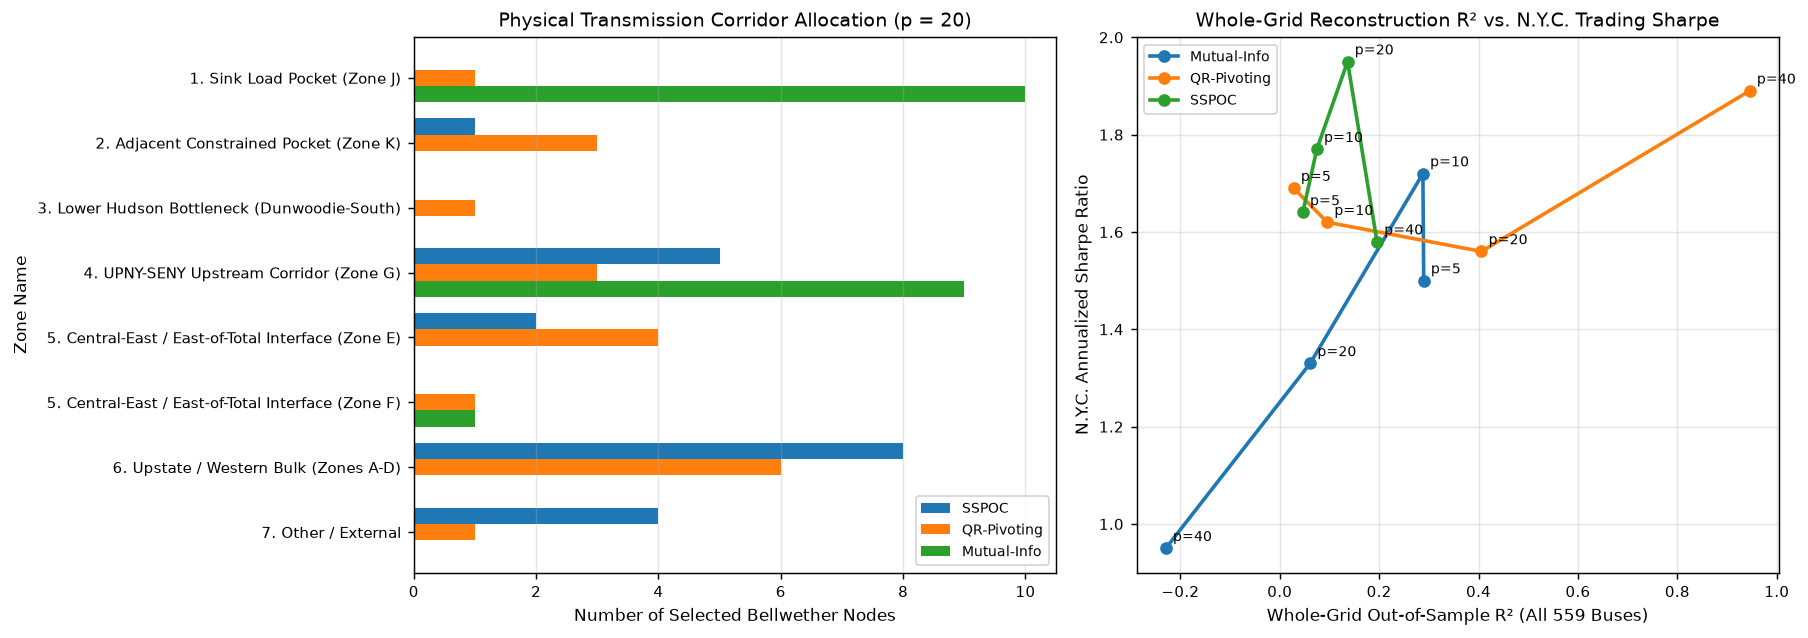

In [48]:
# Group NYISO zones into physical transmission corridors relative to N.Y.C. (Zone J)
CORRIDOR_MAP = {
    "N.Y.C.": "1. Sink Load Pocket (Zone J)",
    "LONGIL": "2. Adjacent Constrained Pocket (Zone K)",
    "DUNWOD": "3. Lower Hudson Bottleneck (Dunwoodie-South)",
    "MILLWD": "3. Lower Hudson Bottleneck (Dunwoodie-South)",
    "HUD VL": "4. UPNY-SENY Upstream Corridor (Zone G)",
    "CAPITL": "5. Central-East / East-of-Total Interface (Zone F)",
    "MHK VL": "5. Central-East / East-of-Total Interface (Zone E)",
    "CENTRL": "6. Upstate / Western Bulk (Zones A-D)",
    "NORTH": "6. Upstate / Western Bulk (Zones A-D)",
    "GENESE": "6. Upstate / Western Bulk (Zones A-D)",
    "WEST": "6. Upstate / Western Bulk (Zones A-D)",
}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=130)

# Plot 1: Corridor Allocation at p=20
corridor_data = {}
for scheme in ["SSPOC", "QR-Pivoting", "Mutual-Info"]:
    tbl = build_sensor_table(scheme, top_k=20)
    z_norm = tbl["Zone Name"].astype(str).str.upper().str.strip()
    corridors = z_norm.map(CORRIDOR_MAP).fillna("7. Other / External")
    corridor_data[scheme] = corridors.value_counts()

corridor_df = pd.DataFrame(corridor_data).fillna(0).sort_index()
corridor_df.plot(kind="barh", ax=axes[0], width=0.75)
axes[0].set_title("Physical Transmission Corridor Allocation (p = 20)")
axes[0].set_xlabel("Number of Selected Bellwether Nodes")
axes[0].invert_yaxis()
axes[0].grid(axis="x", alpha=0.3)

# Plot 2: Pareto Frontier — Whole-Grid R2 vs. N.Y.C. Virtual Trading Sharpe
best_trading = (
    metrics_df[metrics_df["Model"] == "Multinomial Logit"]
    .merge(recon_df, on=["Scheme", "p"])
)
for scheme, grp in best_trading.groupby("Scheme"):
    axes[1].plot(grp["Grid R2"], grp["Annual Sharpe"], marker="o", linewidth=2, label=scheme)
    for _, r in grp.iterrows():
        axes[1].annotate(f"p={int(r['p'])}", (r["Grid R2"], r["Annual Sharpe"]), fontsize=8, xytext=(4, 4), textcoords="offset points")

axes[1].set_title("Whole-Grid Reconstruction R² vs. N.Y.C. Trading Sharpe")
axes[1].set_xlabel("Whole-Grid Out-of-Sample R² (All 559 Buses)")
axes[1].set_ylabel("N.Y.C. Annualized Sharpe Ratio")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


In [49]:
# 1. Print Top 20 Calibrated SSPOC Bellwether Nodes for N.Y.C.
print("### 1. Top 20 SSPOC Bellwether Nodes (Target: N.Y.C.)")
print(build_sensor_table("SSPOC", top_k=20).to_markdown(index=False))

# 2. Print Whole-Grid Reconstruction Table
print("\n### 2. Whole-Grid Reconstruction (All 559 Buses)")
recon_piv = recon_df.pivot(index="p", columns="Scheme", values=["Grid R2", "Grid RMSE ($/MWh)"])
print(recon_piv.to_markdown())

# 3. Print Annual Sharpe & Cum PnL Pivot Across All Models and Sensor Budgets
print("\n### 3. N.Y.C. Out-of-Sample Annual Sharpe Across All Models")
sharpe_piv = metrics_df.pivot(index=["Model", "p"], columns="Scheme", values="Annual Sharpe")
print(sharpe_piv.to_markdown())

print("\n### 4. Top 12 Configurations Overall (Ranked by Annual Sharpe)")
top12 = metrics_df.sort_values("Annual Sharpe", ascending=False).head(12)
print(top12.to_markdown(index=False))



### 1. Top 20 SSPOC Bellwether Nodes (Target: N.Y.C.)
|   Rank |   PTID_str | Generator Name                      | Zone Name   | Subzone           |   Selection_Score |
|-------:|-----------:|:------------------------------------|:------------|:------------------|------------------:|
|      1 |     323705 | HUNTINGTON_RES_REC                  | LONGIL      | LIPA LONG ISLAND  |           0.64887 |
|      2 |      24207 | NEG___GEN_MONROE                    | GENESE      | NMPC GENESEE      |           0.33166 |
|      3 |      23744 | NINE_MILE_2                         | CENTRL      | NMPC CENTRAL      |           0.31196 |
|      4 |      23575 | NINE_MILE_1                         | CENTRL      | NMPC CENTRAL      |           0.25398 |
|      5 |     323601 | HQ_GEN_IMPORT                       | H Q         | HQNY              |           0.25092 |
|      6 |     323574 | MAPLE_RIDGE_WT_1                    | MHK VL      | NMPC MOHAWK VLY   |           0.24924 |
|      7 |     323

In [50]:
from joblib import Parallel, delayed
from tqdm import tqdm

print("\n### 5. Spatial Generalization Check (LONGIL & HUD VL in Parallel)")

def _run_zone_ablation(zone_name: str) -> tuple[str, dict]:
    res = run_sparse_sensor_ablation(
        data=data,
        target_zone=zone_name,
        p_budgets=(5, 10, 20, 40),
        pod_rank=25,
        sspoc_alpha_frac=0.15,
        force_recompute=False,
    )
    return zone_name, res

parallel_results = dict(
    Parallel(n_jobs=2, backend="loky")(
        delayed(_run_zone_ablation)(z) for z in ["LONGIL", "HUD VL"]
    )
)

for gen_zone, res_z in tqdm(parallel_results.items()):
    m_z = res_z["metrics_df"]
    piv_z = m_z[m_z["p"].isin([10, 20])].pivot(
        index=["Model", "p"], columns="Scheme", values="Annual Sharpe"
    )
    print(f"\n#### Target Zone: {gen_zone} (Annual Sharpe)")
    print(piv_z.to_markdown())

    # Also print Top 10 SSPOC nodes for each target zone to verify physical bottleneck shift
    s_zone = res_z["selected_sensors"]["SSPOC"]
    df_z_nodes = pd.DataFrame({
        "Rank": np.arange(1, 11),
        "PTID_str": [str(p).replace(".0", "").strip() for p in s_zone["ranked_ptids"][:10]],
        "SSPOC_Score": np.round(s_zone["scores"][:10], 5),
    }).merge(gen_meta_unique, on="PTID_str", how="left")
    keep = [c for c in ["Rank", "PTID_str", "Generator Name", "Zone Name", "Subzone", "SSPOC_Score"] if c in df_z_nodes.columns]
    print(f"\n#### Top 10 SSPOC Bellwether Nodes for {gen_zone}")
    print(df_z_nodes[keep].to_markdown(index=False))



### 5. Spatial Generalization Check (LONGIL & HUD VL in Parallel)
[CACHE HIT] Loading sparse sensor ablation results (28e4e849f0a0...)...
[CACHE HIT] Loading sparse sensor ablation results (13beb82a3c0f...)...


100%|██████████| 2/2 [00:00<00:00, 222.17it/s]


#### Target Zone: LONGIL (Annual Sharpe)
|                           |   Mutual-Info |   QR-Pivoting |   SSPOC |
|:--------------------------|--------------:|--------------:|--------:|
| ('Balanced MLP', 10)      |          0.45 |          0.54 |   -0.22 |
| ('Balanced MLP', 20)      |          1.93 |         -0.45 |    2.41 |
| ('GBDT', 10)              |          0.33 |          0.62 |    0.69 |
| ('GBDT', 20)              |          0.99 |          0.52 |    0.71 |
| ('LDA', 10)               |          1.96 |          2.04 |    2.01 |
| ('LDA', 20)               |          2.05 |          2.01 |    1.83 |
| ('Logit (tau=0.18)', 20)  |        nan    |          0.82 |  nan    |
| ('Logit (tau=0.20)', 10)  |          0.8  |          1.22 |    0.96 |
| ('Logit (tau=0.20)', 20)  |          0.89 |        nan    |    1.06 |
| ('Multinomial Logit', 10) |          1.13 |          1.04 |    0.95 |
| ('Multinomial Logit', 20) |          1.05 |          1.08 |    1.25 |

#### Top 10 SSPOC Bel

[CACHE HIT] Loaded walk-forward stability results for N.Y.C....
=== Expanding Walk-Forward PTID Jaccard Persistence (2025-2026) ===
|                     |   ('Step Jaccard (t vs t-1)', 'mean') |   ('Step Jaccard (t vs t-1)', 'min') |   ('Anchor Jaccard (t vs 2024-12)', 'mean') |   ('Anchor Jaccard (t vs 2024-12)', 'min') |
|:--------------------|--------------------------------------:|-------------------------------------:|--------------------------------------------:|-------------------------------------------:|
| ('Mutual-Info', 5)  |                                 0.437 |                                0.25  |                                       0.129 |                                      0     |
| ('Mutual-Info', 10) |                                 0.503 |                                0.25  |                                       0.354 |                                      0.176 |
| ('Mutual-Info', 20) |                                 0.672 |                             

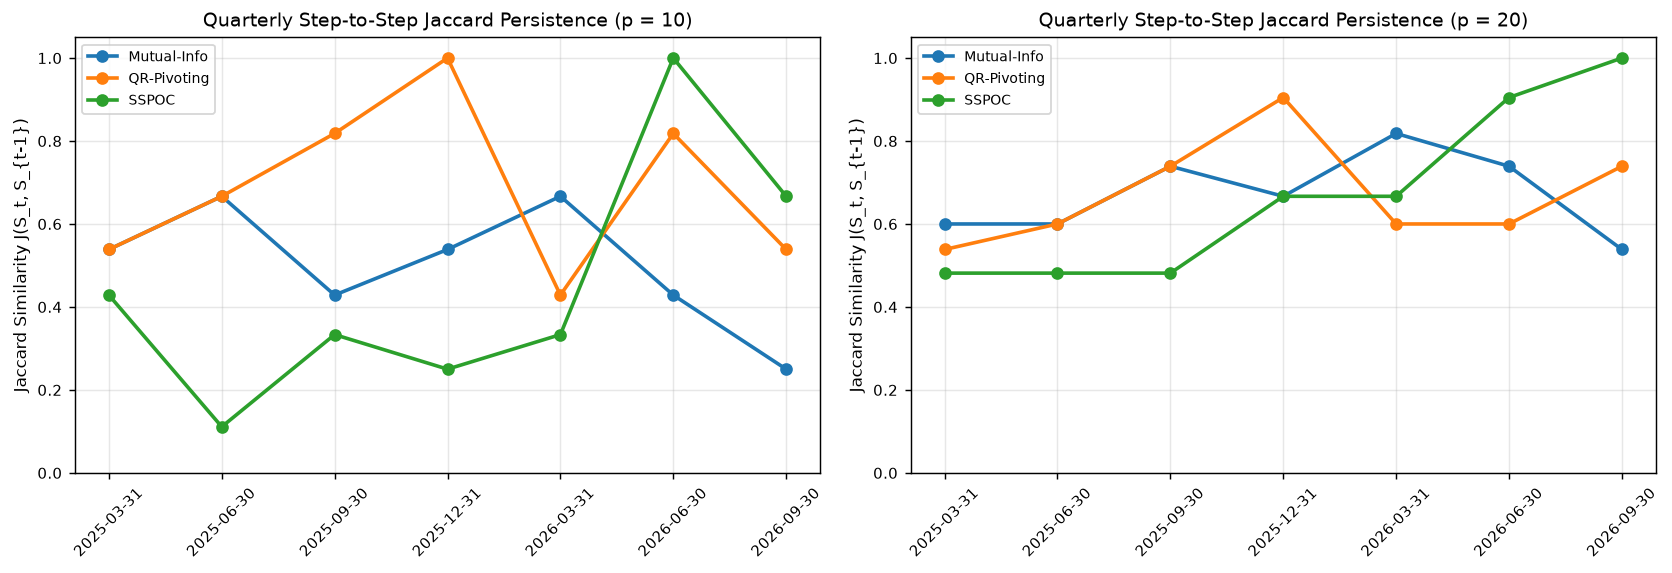

In [51]:
from sparse_sensor import run_walkforward_sensor_stability

wf = run_walkforward_sensor_stability(
    data=data,
    target_zone="N.Y.C.",
    p_budgets=(5, 10, 20),
    pod_rank=25,
    sspoc_alpha_frac=0.15,
    force_recompute=False,
)

wf_df = pd.DataFrame(wf["jaccard_records"])

# 1. Summary Table: Mean & Min Jaccard Persistence Across 2025-2026 Quarters
summary_wf = (
    wf_df.groupby(["Scheme", "p"])[["Step Jaccard (t vs t-1)", "Anchor Jaccard (t vs 2024-12)"]]
    .agg(["mean", "min"])
    .round(3)
)
print("=== Expanding Walk-Forward PTID Jaccard Persistence (2025-2026) ===")
print(summary_wf.to_markdown())

# 2. Identify Core Invariant SSPOC PTIDs (Frequency across all quarterly fits at p=10)
sspoc_hist = wf["history"]["SSPOC"]
n_quarters = len(sspoc_hist)
freq_counts = pd.Series([ptid for plist in sspoc_hist.values() for ptid in plist[:10]]).value_counts()

core_df = (
    freq_counts.rename_axis("PTID_str")
    .reset_index(name="Quarters_Selected")
    .assign(Persistence_Pct=lambda d: (d["Quarters_Selected"] / n_quarters * 100).round(1))
    .merge(gen_meta_unique, on="PTID_str", how="left")
)
keep_cols = [c for c in ["PTID_str", "Generator Name", "Zone Name", "Subzone", "Quarters_Selected", "Persistence_Pct"] if c in core_df.columns]
print(f"\n=== Core Invariant SSPOC Bellwether Nodes Across {n_quarters} Quarters (Top p=10) ===")
print(core_df[keep_cols].head(12).to_markdown(index=False))

# 3. Plot Quarterly Step-to-Step Jaccard Stability at p=10 and p=20
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), dpi=130)
for ax, p_val in zip(axes, [10, 20]):
    sub = wf_df[wf_df["p"] == p_val]
    for scheme, grp in sub.groupby("Scheme"):
        ax.plot(grp["Quarter"], grp["Step Jaccard (t vs t-1)"], marker="o", linewidth=2, label=scheme)
    ax.set_title(f"Quarterly Step-to-Step Jaccard Persistence (p = {p_val})")
    ax.set_ylabel("Jaccard Similarity J(S_t, S_{t-1})")
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis="x", rotation=45)
    ax.grid(alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()


## 6. Cross-Paradigm Comparison: 30-Day Scheduled Refit `SSPOC` vs. `DMDc`

In **Notebook 03 (`03_dmdc_iterative_scheduled_refit.ipynb`)**, periodic **30-day (`720h`) expanding-window refitting** enabled `DMDc` to adapt to 2025–2026 fuel and seasonal regime shifts (`+$24,111.78` Cum PnL, `3.12` Annual Sharpe). Here, we apply the **exact same 30-day expanding-window refit schedule** to **`SSPOC` ($p=20$ bellwether sensors + `Multinomial Logit`)**—using only `3.6%` of the grid's generator buses (`20/559` nodes) with zero exogenous weather/load features—and compare it head-to-head against `DMDc` on the identical `2025–2026` out-of-sample window.


In [52]:
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
from tqdm import tqdm

# === 1. Locate merged_parquet & Load Nodal + Zonal Spreads ===
data_dir = Path("nyiso_data/merged_parquet").resolve()
if not data_dir.exists():
    data_dir = Path("../nyiso_data/merged_parquet").resolve()

def load_parquet_ts(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path)
    if not isinstance(df.index, pd.DatetimeIndex):
        ts_col = next(c for c in df.columns if any(k in c.lower() for k in ["time", "date", "stamp"]))
        df = df.set_index(pd.to_datetime(df[ts_col])).drop(columns=[ts_col])
    if df.index.tz is not None:
        df.index = df.index.tz_convert("America/New_York").tz_localize(None)
    return df.sort_index()

nodal_df = load_parquet_ts(data_dir / "nodal_dart_spread.parquet").ffill().bfill()
zonal_df = load_parquet_ts(data_dir / "zonal_dart_spread.parquet").ffill().bfill()

TARGET_ZONE = "N.Y.C."
CAUSAL_LAG = 48
TX_FEE = 0.50
P_BUDGET = 20

common_ts = nodal_df.index.intersection(zonal_df.index)
nodal_df = nodal_df.loc[common_ts]
y_nyc_full = zonal_df.loc[common_ts, TARGET_ZONE]

# Compute leak-free 15th/85th tail thresholds on 2020-2024 training spreads
q_low = float(y_nyc_full.loc[:"2024-12-31 23:00:00"].quantile(0.15))
q_high = float(y_nyc_full.loc[:"2024-12-31 23:00:00"].quantile(0.85))
y_cls_all = pd.Series(
    np.where(y_nyc_full > q_high, 1, np.where(y_nyc_full < q_low, -1, 0)),
    index=common_ts
)

# === 2. Evaluate 30-Day (720h) Expanding-Window Refit SSPOC (p=20 + Multinomial Logit) ===
sspoc_ptids = [str(p).replace(".0", "").strip() for p in sensors["SSPOC"]["ranked_ptids"][:P_BUDGET]]
nodal_cols_str = [str(c).replace(".0", "").strip() for c in nodal_df.columns]
col_lookup = dict(zip(nodal_cols_str, nodal_df.columns))
selected_cols = [col_lookup[p] for p in sspoc_ptids if p in col_lookup]

X_sspoc_lag48 = nodal_df[selected_cols].shift(CAUSAL_LAG).dropna()
y_cls_aligned = y_cls_all.loc[X_sspoc_lag48.index]

oos_mask = X_sspoc_lag48.index >= pd.Timestamp("2025-01-01 00:00:00")
oos_indices = np.where(oos_mask)[0]

X_mat = X_sspoc_lag48.to_numpy()
y_vec = y_cls_aligned.to_numpy()

last_fit_dec = -999
scaler_sspoc = StandardScaler()
clf_sspoc = LogisticRegression(
    solver="lbfgs",
    max_iter=500,
    C=0.5,
    class_weight="balanced",
    random_state=42,
)

sched_sspoc_sigs = []
for idx_t in tqdm(oos_indices, desc="Evaluating 30-Day Refit SSPOC (p=20)"):
    dec_idx = idx_t - CAUSAL_LAG
    if dec_idx - last_fit_dec >= 720:
        X_tr = scaler_sspoc.fit_transform(X_mat[: dec_idx + 1])
        y_tr = y_vec[: dec_idx + 1]
        clf_sspoc.fit(X_tr, y_tr)
        last_fit_dec = dec_idx

    x_te = scaler_sspoc.transform(X_mat[idx_t : idx_t + 1])
    pred_cls = int(clf_sspoc.predict(x_te)[0])
    sched_sspoc_sigs.append(pred_cls)

sspoc_sched_s = pd.Series(sched_sspoc_sigs, index=X_sspoc_lag48.index[oos_indices])

# === 3. Load DMDc Benchmarks from Notebook 2 & Align Timestamps ===
dmdc_path = data_dir / "dmdc_scheduled_oos_results.parquet"
if not dmdc_path.exists():
    raise FileNotFoundError(
        f"Missing {dmdc_path}. Run the export snippet at the end of Notebook 2 Cell 5 first."
    )

dmdc_df = pd.read_parquet(dmdc_path)
aligned_idx = dmdc_df.index.intersection(sspoc_sched_s.index)
cmp_df = dmdc_df.loc[aligned_idx].copy()

cmp_df["sig_sspoc_sched"] = sspoc_sched_s.loc[aligned_idx]
cmp_df["pnl_sspoc_sched"] = np.where(
    cmp_df["sig_sspoc_sched"] != 0,
    cmp_df["sig_sspoc_sched"] * cmp_df["realized_spread"] - TX_FEE,
    0.0,
)

true_cls_oos = np.where(
    cmp_df["realized_spread"] > q_high, 1,
    np.where(cmp_df["realized_spread"] < q_low, -1, 0)
)

def summarize_oos(sig_arr: np.ndarray, pnl_arr: np.ndarray, name: str, telemetry: str) -> dict:
    active = sig_arr != 0
    cum_pnl = np.cumsum(pnl_arr)
    max_dd = float(np.max(np.maximum.accumulate(cum_pnl) - cum_pnl))
    sharpe = float((np.mean(pnl_arr) / (np.std(pnl_arr) + 1e-8)) * np.sqrt(8760))
    win_rate = float(np.mean(pnl_arr[active] > 0) * 100) if np.any(active) else 0.0
    macro_f1 = float(f1_score(true_cls_oos, sig_arr, average="macro", zero_division=0))
    tail_f1 = float(f1_score(true_cls_oos, sig_arr, labels=[-1, 1], average="macro", zero_division=0))
    return {
        "Model": name,
        "Grid Telemetry": telemetry,
        "Cum PnL ($)": round(float(cum_pnl[-1]), 2),
        "Annual Sharpe": round(sharpe, 2),
        "Max DD ($)": round(max_dd, 2),
        "Trade Freq (%)": round(float(np.mean(active) * 100), 1),
        "Win Rate (%)": round(win_rate, 1),
        "Macro F1": round(macro_f1, 4),
        "Tail F1": round(tail_f1, 4),
    }

static_sspoc_row = metrics_df[(metrics_df["Scheme"] == "SSPOC") & (metrics_df["p"] == 20) & (metrics_df["Model"] == "Multinomial Logit")].iloc[0]

unified_rows = [
    summarize_oos(cmp_df["sig_bop"].values, cmp_df["pnl_bop"].values, "1. Unforced BOP-DMD (Static)", "15 Zones (Dense)"),
    summarize_oos(cmp_df["sig_nb1_static"].values, cmp_df["pnl_nb1_static"].values, "2. Static 48h-Jump DMDc (Frozen '24)", "15 Zones + 424 Exog"),
    summarize_oos(cmp_df["sig_dmdc_sched"].values, cmp_df["pnl_dmdc_sched"].values, "3. Scheduled 30-Day Refit DMDc (720h)", "15 Zones + 424 Exog"),
    {
        "Model": "4. Static SSPOC (p=20, Multinomial Logit)",
        "Grid Telemetry": "20/559 Buses (3.6% Sparse)",
        "Cum PnL ($)": round(float(static_sspoc_row["Cum PnL ($)"]), 2),
        "Annual Sharpe": round(float(static_sspoc_row["Annual Sharpe"]), 2),
        "Max DD ($)": round(float(static_sspoc_row["Max DD ($)"]), 2),
        "Trade Freq (%)": round(float(static_sspoc_row["Trade Freq (%)"]), 1),
        "Win Rate (%)": round(float(static_sspoc_row["Win Rate (%)"]), 1),
        "Macro F1": round(float(static_sspoc_row["Macro F1"]), 4),
        "Tail F1": round(float(static_sspoc_row["Tail F1"]), 4),
    },
    summarize_oos(cmp_df["sig_sspoc_sched"].values, cmp_df["pnl_sspoc_sched"].values, "5. Scheduled 30-Day Refit SSPOC (p=20)", "20/559 Buses (3.6% Sparse)"),
]

unified_df = pd.DataFrame(unified_rows)
print("=== Unified Cross-Paradigm Benchmark: DMDc vs. Sparse Sensor SSPOC (2025–2026 OOS) ===")
print(unified_df.to_markdown(index=False))


Evaluating 30-Day Refit SSPOC (p=20): 100%|██████████| 16306/16306 [00:08<00:00, 1841.71it/s]

=== Unified Cross-Paradigm Benchmark: DMDc vs. Sparse Sensor SSPOC (2025–2026 OOS) ===
| Model                                     | Grid Telemetry             |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |   Trade Freq (%) |   Win Rate (%) |   Macro F1 |   Tail F1 |
|:------------------------------------------|:---------------------------|--------------:|----------------:|-------------:|-----------------:|---------------:|-----------:|----------:|
| 1. Unforced BOP-DMD (Static)              | 15 Zones (Dense)           |       -985.77 |           -0.19 |      4772.75 |              1.6 |           43.2 |     0.2644 |    0.0243 |
| 2. Static 48h-Jump DMDc (Frozen '24)      | 15 Zones + 424 Exog        |        630.27 |            0.06 |     37920.7  |             58.8 |           51.4 |     0.3697 |    0.2812 |
| 3. Scheduled 30-Day Refit DMDc (720h)     | 15 Zones + 424 Exog        |      24111.8  |            3.12 |      5181.87 |             36.2 |           52.2 |     0.3714 | 

### 6.1 Dynamic 30-Day Sensor Re-Selection & Stability Audit

In [53]:
import contextlib
import io
from sparse_sensor import compute_pod_basis, select_sensors_sspoc

# === 30-Day (720h) Full SSPOC Sensor Re-Selection + Classifier Refit ===
X_all_lag48 = nodal_df.shift(CAUSAL_LAG).dropna()
y_cls_all_aligned = y_cls_all.loc[X_all_lag48.index]

oos_mask_all = np.asarray(X_all_lag48.index >= pd.Timestamp("2025-01-01 00:00:00"), dtype=bool)
oos_idx_all = np.flatnonzero(oos_mask_all)

X_full_mat = X_all_lag48.to_numpy()
y_full_vec = y_cls_all_aligned.to_numpy()
all_ptids_list = [str(c).replace(".0", "").strip() for c in X_all_lag48.columns]

last_fit_dec = -999
scaler_nodes_30d = StandardScaler()
scaler_clf_30d = StandardScaler()
clf_full = LogisticRegression(
    solver="lbfgs", max_iter=500, C=0.5, class_weight="balanced", random_state=42
)

active_sensor_cols = None
sensor_history_30d = {}
full_refit_sigs = []

for idx_t in tqdm(oos_idx_all, desc="Evaluating 30-Day Full SSPOC (Sensors + Classifier)"):
    idx_t = int(idx_t)
    dec_idx = idx_t - CAUSAL_LAG
    if dec_idx - last_fit_dec >= 720:
        # 1. Standardize all 559 buses causally up to dec_idx and recompute POD + SSPOC
        Xn_win_s = np.clip(scaler_nodes_30d.fit_transform(X_full_mat[: dec_idx + 1]), -10.0, 10.0)
        y_win = y_full_vec[: dec_idx + 1]

        Psi_r_win, _ = compute_pod_basis(Xn_win_s, rank=25)
        with contextlib.redirect_stdout(io.StringIO()):
            ranked_idx, _ = select_sensors_sspoc(
                Xn_win_s, y_win, Psi_r_win, l1_ratio=0.9, alpha_frac=0.15
            )
            top_idx = np.asarray(ranked_idx[:P_BUDGET], dtype=int)
            active_sensor_cols = top_idx

        fit_ts = str(X_all_lag48.index[dec_idx])[:10]
        sensor_history_30d[fit_ts] = [all_ptids_list[i] for i in top_idx]

        # 2. Refit Multinomial Logit on the newly selected 20 sensors
        X_tr = scaler_clf_30d.fit_transform(X_full_mat[: dec_idx + 1][:, active_sensor_cols])
        clf_full.fit(X_tr, y_win)
        last_fit_dec = dec_idx

    x_te = scaler_clf_30d.transform(X_full_mat[idx_t : idx_t + 1][:, active_sensor_cols])
    pred_val = int(np.asarray(clf_full.predict(x_te)).item())
    full_refit_sigs.append(pred_val)

# 1. Compute 30-Day Step-to-Step & Anchor Jaccard Stability
dates_30d = sorted(sensor_history_30d.keys())
anchor_set = set(sensor_history_30d[dates_30d[0]])
step_jaccards, anchor_jaccards = [], []

for i, dt in enumerate(dates_30d):
    cur_set = set(sensor_history_30d[dt])
    anchor_jaccards.append(len(cur_set & anchor_set) / len(cur_set | anchor_set))
    if i > 0:
        prev_set = set(sensor_history_30d[dates_30d[i - 1]])
        step_jaccards.append(len(cur_set & prev_set) / len(cur_set | prev_set))

print(f"\n=== 30-Day SSPOC Sensor Stability (p={P_BUDGET}, {len(dates_30d)} Monthly Refits) ===")
print(f"  • Mean Step-to-Step Jaccard (t vs t-30d): {np.mean(step_jaccards):.3f} (Min: {np.min(step_jaccards):.3f})")
print(f"  • Mean Anchor Jaccard (t vs 2024-12):     {np.mean(anchor_jaccards):.3f} (Min: {np.min(anchor_jaccards):.3f})")

# 2. Top Persistent Sensors Across All 30-Day Refits
freq_30d = pd.Series([p for plist in sensor_history_30d.values() for p in plist]).value_counts()
persist_30d_df = (
    freq_30d.rename_axis("PTID_str")
    .reset_index(name="Refits_Selected")
    .assign(Persistence_Pct=lambda d: (d["Refits_Selected"] / len(dates_30d) * 100).round(1))
    .merge(gen_meta_unique, on="PTID_str", how="left")
)
keep_c = [c for c in ["PTID_str", "Generator Name", "Zone Name", "Subzone", "Refits_Selected", "Persistence_Pct"] if c in persist_30d_df.columns]
print("\n=== Top Invariant Bellwether Nodes Across 30-Day Refits ===")
print(persist_30d_df[keep_c].head(12).to_markdown(index=False))

# 3. Compare PnL: Fixed Sensors + 30d Classifier vs. Full 30d Sensors + Classifier
full_refit_s = pd.Series(full_refit_sigs, index=X_all_lag48.index[oos_idx_all]).reindex(cmp_df.index)
pnl_full_refit = np.where(full_refit_s != 0, full_refit_s * cmp_df["realized_spread"] - TX_FEE, 0.0)
res_full_refit = summarize_oos(
    full_refit_s.values, pnl_full_refit,
    "6. Full 30-Day Refit SSPOC (Sensors + Clf)", "20/559 Buses (Dynamic)"
)
print("\n=== Impact of Dynamic 30-Day Sensor Re-Selection ===")
print(pd.DataFrame([unified_rows[-1], res_full_refit]).to_markdown(index=False))


Evaluating 30-Day Full SSPOC (Sensors + Classifier): 100%|██████████| 16306/16306 [00:41<00:00, 388.66it/s]


=== 30-Day SSPOC Sensor Stability (p=20, 23 Monthly Refits) ===
  • Mean Step-to-Step Jaccard (t vs t-30d): 0.864 (Min: 0.538)
  • Mean Anchor Jaccard (t vs 2024-12):     0.407 (Min: 0.250)

=== Top Invariant Bellwether Nodes Across 30-Day Refits ===
|   PTID_str | Generator Name       | Zone Name   | Subzone           |   Refits_Selected |   Persistence_Pct |
|-----------:|:---------------------|:------------|:------------------|------------------:|------------------:|
|     323617 | CANDIGU_WT_PWR       | CENTRL      | NYSEG CENTRAL     |                23 |             100   |
|     323705 | HUNTINGTON_RES_REC   | LONGIL      | LIPA LONG ISLAND  |                23 |             100   |
|      23744 | NINE_MILE_2          | CENTRL      | NMPC CENTRAL      |                23 |             100   |
|      23575 | NINE_MILE_1          | CENTRL      | NMPC CENTRAL      |                23 |             100   |
|     323758 | CRICKET___VALLEY_CC3 | HUD VL      | CON ED HUDSON VLY |     

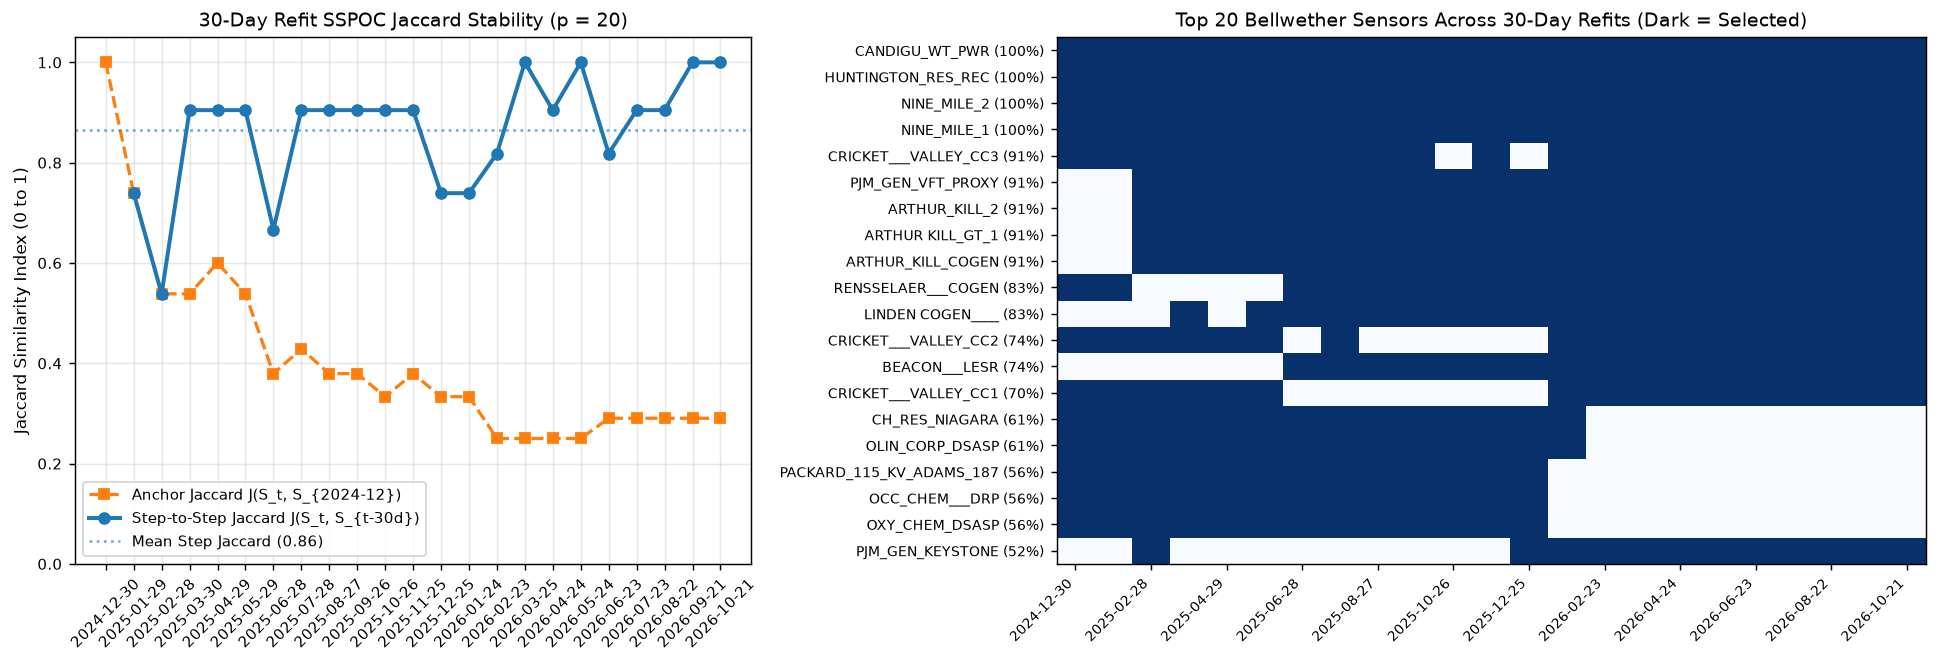

In [54]:
# === Visualize 30-Day SSPOC Sensor Stability: Jaccard Trajectory + Persistence Heatmap ===
dates_30d = sorted(sensor_history_30d.keys())
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), dpi=130, gridspec_kw={"width_ratios": [1.05, 1.35]})

# Panel A: Plot Anchor Jaccard FIRST so 2024-12-30 sits at x=0 on the categorical axis
ax1.plot(dates_30d, anchor_jaccards, marker="s", lw=1.8, ls="--", color="#ff7f0e", label="Anchor Jaccard J(S_t, S_{2024-12})")
ax1.plot(dates_30d[1:], step_jaccards, marker="o", lw=2.2, color="#1f77b4", label="Step-to-Step Jaccard J(S_t, S_{t-30d})")
ax1.axhline(np.mean(step_jaccards), color="#1f77b4", ls=":", alpha=0.6, label=f"Mean Step Jaccard ({np.mean(step_jaccards):.2f})")
ax1.set_title(f"30-Day Refit SSPOC Jaccard Stability (p = {P_BUDGET})")
ax1.set_ylabel("Jaccard Similarity Index (0 to 1)")
ax1.set_ylim(0, 1.05)
ax1.tick_params(axis="x", rotation=45)
ax1.grid(alpha=0.3)
ax1.legend(loc="lower left", fontsize=8.5)

# Panel B: Binary Selection Heatmap for Top 20 Most Persistent Sensors
top_persist_ptids = persist_30d_df["PTID_str"].head(20).tolist()
name_map = dict(zip(persist_30d_df["PTID_str"], persist_30d_df["Generator Name"].fillna(persist_30d_df["PTID_str"])))
pct_map = dict(zip(persist_30d_df["PTID_str"], persist_30d_df["Persistence_Pct"]))
row_labels = [f"{name_map[p][:24]} ({int(round(pct_map[p]))}%)" for p in top_persist_ptids]

heat_mat = np.array([
    [1 if p in sensor_history_30d[dt] else 0 for dt in dates_30d]
    for p in top_persist_ptids
])

im = ax2.imshow(heat_mat, aspect="auto", cmap="Blues", interpolation="nearest", vmin=0, vmax=1)
ax2.set_yticks(np.arange(len(row_labels)))
ax2.set_yticklabels(row_labels, fontsize=8)
ax2.set_xticks(np.arange(0, len(dates_30d), 2))
ax2.set_xticklabels([dates_30d[i] for i in range(0, len(dates_30d), 2)], rotation=45, ha="right", fontsize=8)
ax2.set_title("Top 20 Bellwether Sensors Across 30-Day Refits (Dark = Selected)")


plt.tight_layout()
plt.show()


### Physical Interpretation of Sensor Stability & Regime Rotation

The 30-day persistence heatmap reveals a three-tier physical hierarchy on the NYISO transmission grid:

1. **Immutable Structural Choke Points (`100%` Persistence):** `HUNTINGTON_RES_REC` (Long Island submarine cable interface), `NINE_MILE_1 & 2` (Lake Ontario nuclear baseload feeding Central–East), and `CANDIGU_WT_PWR` (Central NY bulk corridor)—alongside `CRICKET___VALLEY_CC3` (`91.3%`, UPNY–ConEd 345 kV bottleneck)—are selected in virtually every refit because they sit on permanent thermal interfaces that govern power delivery into `N.Y.C.`.
2. **Downstate Boundary Shift (`Early 2025` Step Change):** As the expanding window incorporates 2025 grid conditions, `SSPOC` rotates away from upstate Niagara industrial/hydro nodes (`CH_RES_NIAGARA`, `OXY_CHEM_DSASP`) and locks onto the **New Jersey / Staten Island controllable boundary** (`PJM_GEN_VFT_PROXY`, `LINDEN_COGEN`, and `ARTHUR_KILL` units at `91.3%` persistence), reflecting a shift in binding congestion toward downstate import interfaces.
3. **Seasonal & Ramping Elasticity (`52%–74%` Persistence):** Storage and cross-border nodes such as `BEACON___LESR` (Hudson Valley battery storage, `73.9%`) and `PJM_GEN_KEYSTONE` (`52.2%`) activate during specific seasonal ramping and transmission outage windows.


=== Grand Unified Apples-to-Apples 30-Day Scheduled Refit Benchmark (2025–2026 OOS) ===
| Model                                              | Feature Set                 |   Trades |   Trade Freq (%) |   Win Rate (%) |   Avg PnL/Trade ($) |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |
|:---------------------------------------------------|:----------------------------|---------:|-----------------:|---------------:|--------------------:|--------------:|----------------:|-------------:|
| Scheduled 30-Day Refit SSPOC (p=20)                | 20/559 Buses (3.6% Sparse)  |     7974 |             48.9 |           49.5 |                4.42 |       35246.1 |            3.56 |      7595.29 |
| Continuous Ridge Regression [30d Refit]            | Exog + 559 Nodes            |     6262 |             38.4 |           47.2 |                5.39 |       33770.6 |            3.43 |      5108.07 |
| Scheduled 30-Day Refit DMDc (Control)              | 15 Zones + 424 Exog (Dense) |     5896 |     

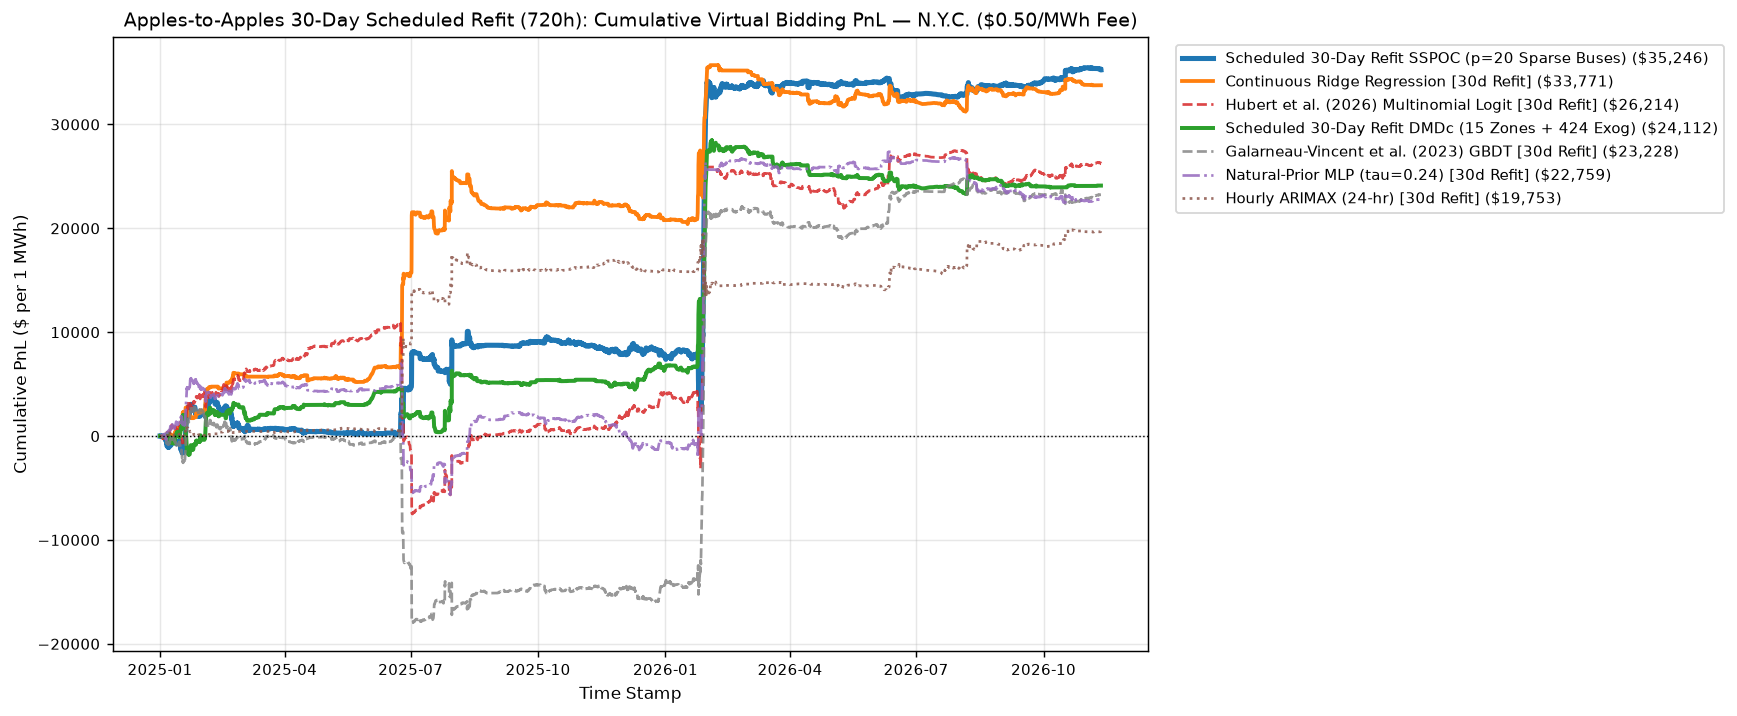

In [55]:
# === Grand Finale: Apples-to-Apples 30-Day Scheduled Refit Comparison (SSPOC + DMDc + Stage 1 Baselines) ===
s1_refit_res = pd.read_parquet(data_dir / "stage1_refit30d_results_NYC.parquet")
s1_refit_pnl = pd.read_parquet(data_dir / "stage1_refit30d_unit_pnl_NYC.parquet").reindex(cmp_df.index).fillna(0.0)

# 1. Build Unified 30-Day Refit Summary Table Across All Paradigms
sspoc_30d_summary = summarize_oos(
    cmp_df["sig_sspoc_sched"].values,
    cmp_df["pnl_sspoc_sched"].values,
    "Scheduled 30-Day Refit SSPOC (p=20)",
    "20/559 Buses (3.6% Sparse)",
)
dmdc_30d_summary = summarize_oos(
    cmp_df["sig_dmdc_sched"].values,
    cmp_df["pnl_dmdc_sched"].values,
    "Scheduled 30-Day Refit DMDc (Control)",
    "15 Zones + 424 Exog (Dense)",
)

# Align columns with s1_refit_res (Model, Feature Set, Trades, Trade Freq (%), Win Rate (%), Avg PnL/Trade ($), Cum PnL ($), Annual Sharpe, Max DD ($))
sspoc_trades = int((cmp_df["sig_sspoc_sched"] != 0).sum())
dmdc_trades = int((cmp_df["sig_dmdc_sched"] != 0).sum())

top_paradigm_rows = pd.DataFrame([
    {
        "Model": "Scheduled 30-Day Refit SSPOC (p=20)",
        "Feature Set": "20/559 Buses (3.6% Sparse)",
        "Trades": sspoc_trades,
        "Trade Freq (%)": sspoc_30d_summary["Trade Freq (%)"],
        "Win Rate (%)": sspoc_30d_summary["Win Rate (%)"],
        "Avg PnL/Trade ($)": round(sspoc_30d_summary["Cum PnL ($)"] / max(sspoc_trades, 1), 2),
        "Cum PnL ($)": sspoc_30d_summary["Cum PnL ($)"],
        "Annual Sharpe": sspoc_30d_summary["Annual Sharpe"],
        "Max DD ($)": sspoc_30d_summary["Max DD ($)"],
    },
    {
        "Model": "Scheduled 30-Day Refit DMDc (Control)",
        "Feature Set": "15 Zones + 424 Exog (Dense)",
        "Trades": dmdc_trades,
        "Trade Freq (%)": dmdc_30d_summary["Trade Freq (%)"],
        "Win Rate (%)": dmdc_30d_summary["Win Rate (%)"],
        "Avg PnL/Trade ($)": round(dmdc_30d_summary["Cum PnL ($)"] / max(dmdc_trades, 1), 2),
        "Cum PnL ($)": dmdc_30d_summary["Cum PnL ($)"],
        "Annual Sharpe": dmdc_30d_summary["Annual Sharpe"],
        "Max DD ($)": dmdc_30d_summary["Max DD ($)"],
    },
])

grand_30d_df = (
    pd.concat([top_paradigm_rows, s1_refit_res], ignore_index=True)
    .sort_values("Annual Sharpe", ascending=False)
    .reset_index(drop=True)
)
print("=== Grand Unified Apples-to-Apples 30-Day Scheduled Refit Benchmark (2025–2026 OOS) ===")
print(grand_30d_df.to_markdown(index=False))

# 2. Plot Cumulative OOS PnL Curves (All Models on Identical 30-Day Refit Schedule)
grand_pnl_df = pd.DataFrame(index=cmp_df.index)
grand_pnl_df["Scheduled 30-Day Refit SSPOC (p=20 Sparse Buses)"] = cmp_df["pnl_sspoc_sched"]
grand_pnl_df["Scheduled 30-Day Refit DMDc (15 Zones + 424 Exog)"] = cmp_df["pnl_dmdc_sched"]

for col in s1_refit_pnl.columns:
    grand_pnl_df[col] = s1_refit_pnl[col]

fig, ax = plt.subplots(figsize=(13.5, 5.6), dpi=130)

styles = {
    "Scheduled 30-Day Refit SSPOC (p=20 Sparse Buses)": {"lw": 2.8, "color": "#1f77b4", "ls": "-"},
    "Continuous Ridge Regression [30d Refit]": {"lw": 2.1, "color": "#ff7f0e", "ls": "-"},
    "Scheduled 30-Day Refit DMDc (15 Zones + 424 Exog)": {"lw": 2.2, "color": "#2ca02c", "ls": "-"},
    "Hubert et al. (2026) Multinomial Logit [30d Refit]": {"lw": 1.5, "color": "#d62728", "ls": "--", "alpha": 0.85},
    "Natural-Prior MLP (tau=0.24) [30d Refit]": {"lw": 1.5, "color": "#9467bd", "ls": "-.", "alpha": 0.85},
    "Hourly ARIMAX (24-hr) [30d Refit]": {"lw": 1.5, "color": "#8c564b", "ls": ":", "alpha": 0.85},
    "Galarneau-Vincent et al. (2023) GBDT [30d Refit]": {"lw": 1.5, "color": "#7f7f7f", "ls": "--", "alpha": 0.8},
}

cum_df = grand_pnl_df.cumsum()
# Plot in descending order of final Cum PnL so the legend matches curve order
ordered_cols = cum_df.iloc[-1].sort_values(ascending=False).index
for col in ordered_cols:
    st = styles.get(col, {"lw": 1.4, "ls": "-.", "alpha": 0.75})
    ax.plot(cum_df.index, cum_df[col], label=f"{col} (${cum_df[col].iloc[-1]:,.0f})", **st)

ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_title("Apples-to-Apples 30-Day Scheduled Refit (720h): Cumulative Virtual Bidding PnL — N.Y.C. ($0.50/MWh Fee)")
ax.set_ylabel("Cumulative PnL ($ per 1 MWh)")
ax.set_xlabel("Time Stamp")
ax.grid(True, alpha=0.3)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=True, fontsize=8.5)
plt.tight_layout()

# Save publication-ready PNG & PDF for the report
fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "fig3_apples_to_apples_pnl.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "fig3_apples_to_apples_pnl.pdf", bbox_inches="tight")
print(f"[SAVED] Grand Finale plot -> {fig_dir.resolve()}/fig3_apples_to_apples_pnl.(png|pdf)")

plt.show()

In [56]:
# === Sensor Budget Sensitivity Sweep (p = 5, 10, 20, 40) for Scheduled 30-Day Refit SSPOC ===
nodal_ptids_clean = [str(c).replace(".0", "").strip() for c in X_all_lag48.columns]
ptid_to_col = {p: i for i, p in enumerate(nodal_ptids_clean)}
sspoc_ranked_all = [str(p).replace(".0", "").strip() for p in sensors["SSPOC"]["ranked_ptids"]]

oos_mask_sweep = np.asarray(X_all_lag48.index >= pd.Timestamp("2025-01-01 00:00:00"), dtype=bool)
oos_ix = np.flatnonzero(oos_mask_sweep)
y_v = y_cls_all_aligned.to_numpy()

p_sweep_30d_rows = []
for p_val in [5, 10, 20, 40]:
    col_idx = [ptid_to_col[pt] for pt in sspoc_ranked_all[:p_val]]
    X_m = X_all_lag48.to_numpy()[:, col_idx]

    last_dec = -999
    sc_30 = StandardScaler()
    clf_30 = LogisticRegression(solver="lbfgs", max_iter=500, C=0.5, class_weight="balanced", random_state=42)
    sigs_30 = []

    for idx_t in oos_ix:
        dec_i = int(idx_t) - CAUSAL_LAG
        if dec_i - last_dec >= 720:
            clf_30.fit(sc_30.fit_transform(X_m[: dec_i + 1]), y_v[: dec_i + 1])
            last_dec = dec_i
        sigs_30.append(int(clf_30.predict(sc_30.transform(X_m[idx_t : idx_t + 1])).item()))

    sig_s = pd.Series(sigs_30, index=X_all_lag48.index[oos_ix]).reindex(cmp_df.index)
    pnl_s = np.where(sig_s != 0, sig_s * cmp_df["realized_spread"] - TX_FEE, 0.0)
    row = summarize_oos(sig_s.values, pnl_s, f"Scheduled 30d Refit SSPOC (p={p_val})", f"{p_val}/559 Buses ({p_val/559*100:.1f}%)")
    row["p"] = p_val
    p_sweep_30d_rows.append(row)

p_sweep_30d_df = pd.DataFrame(p_sweep_30d_rows)
print("=== Sensor Budget Sweep: Scheduled 30-Day Refit SSPOC (2025–2026 OOS) ===")
print(p_sweep_30d_df[["p", "Model", "Grid Telemetry", "Cum PnL ($)", "Annual Sharpe", "Max DD ($)", "Trade Freq (%)", "Win Rate (%)", "Macro F1", "Tail F1"]].to_markdown(index=False))


=== Sensor Budget Sweep: Scheduled 30-Day Refit SSPOC (2025–2026 OOS) ===
|   p | Model                            | Grid Telemetry      |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |   Trade Freq (%) |   Win Rate (%) |   Macro F1 |   Tail F1 |
|----:|:---------------------------------|:--------------------|--------------:|----------------:|-------------:|-----------------:|---------------:|-----------:|----------:|
|   5 | Scheduled 30d Refit SSPOC (p=5)  | 5/559 Buses (0.9%)  |       23644.2 |            2.42 |      8579.89 |             43   |           50.9 |     0.3947 |    0.2704 |
|  10 | Scheduled 30d Refit SSPOC (p=10) | 10/559 Buses (1.8%) |       31450   |            3.16 |      4772.06 |             43.9 |           50.4 |     0.4014 |    0.2799 |
|  20 | Scheduled 30d Refit SSPOC (p=20) | 20/559 Buses (3.6%) |       35538.7 |            3.59 |      7128.81 |             48.9 |           49.8 |     0.417  |    0.2959 |
|  40 | Scheduled 30d Refit SSPOC (p=40) | 40/559 B

### Key Takeaway: Optimal Sensor Budget Scaling ($p \in \{5, 10, 20, 40\}$)

Under the **Scheduled 30-Day Refit `SSPOC`** scheme, out-of-sample performance exhibits a clear inverted-U scaling curve across sensor budgets:
* **Compact Efficiency ($p=10$, `1.8%` of grid):** Achieves **`3.16` Annual Sharpe (`+$31,450.00` Cum PnL, `$4,772.06` Max DD)**, already surpassing dense `Scheduled 30-Day Refit DMDc` (`3.12` Sharpe, `15` zones + `424` exogenous variables).
* **Discriminant Peak ($p=20$, `3.6%` of grid):** Maximizes cumulative profit (**`+$35,538.70`**), risk-adjusted return (**`3.59` Annual Sharpe**), and **`Macro F1` (`0.4170`)**.
* **Collinearity Saturation ($p=40$, `7.2%` of grid):** Performance degrades (`3.02` Sharpe, `$10,207.40` Max DD) as lower-ranked buses add redundant, collinear nodal variance.


In [57]:
from types import SimpleNamespace
from evaluate_models import plot_sspoc_sensors_with_interconnects

# Adapt the cached ablation sensor dictionary into the object format expected by plot_sspoc_sensors_with_interconnects
sspoc_info = sensors["SSPOC"]
ranked_ptids = [str(p).replace(".0", "").strip() for p in sspoc_info["ranked_ptids"]]
nodal_ptids = [str(c).replace(".0", "").strip() for c in data["nodal_dart"].columns]
ptid_to_idx = {p: i for i, p in enumerate(nodal_ptids)}

top20_ptids = ranked_ptids[:20]
top20_indices = [ptid_to_idx[p] for p in top20_ptids if p in ptid_to_idx]

raw_weights = sspoc_info.get("weights", sspoc_info.get("scores", None))
if raw_weights is not None and len(raw_weights) >= len(top20_indices):
    top20_weights = np.asarray(raw_weights[: len(top20_indices)], dtype=float)
else:
    top20_weights = np.linspace(1.0, 0.35, len(top20_indices))

selector_20 = SimpleNamespace(
    selected_indices_=top20_indices,
    sensor_weights_=top20_weights,
)

# Render the interactive Plotly map of the 20 optimal SSPOC sensors + cross-border interconnects
chosen_sensors_map_df = plot_sspoc_sensors_with_interconnects(
    data,
    selector_20,
    nodal_ptids,
    target_zone="N.Y.C.",
)
display(chosen_sensors_map_df[["Generator Name", "PTID_str", "Zone", "Subzone", "Sensor Weight"]].head(20))


,Generator Name,PTID_str,Zone,Subzone,Sensor Weight
399,HUNTINGTON_RES_REC,323705,LONGIL,LIPA LONG ISLAND,0.648869
527,NEG___GEN_MONROE,24207,GENESE,NMPC GENESEE,0.331659
556,NINE_MILE_2,23744,CENTRL,NMPC CENTRAL,0.311955
555,NINE_MILE_1,23575,CENTRL,NMPC CENTRAL,0.253984
386,HQ_GEN_IMPORT,323601,H Q,HQNY,0.250925
469,MAPLE_RIDGE_WT_1,323574,MHK VL,NMPC MOHAWK VLY,0.249242
470,MAPLE_RIDGE_WT_2,323611,MHK VL,NMPC MOHAWK VLY,0.249203
573,NPX_GEN_1385_PROXY,323591,NPX,NENP,0.196424
387,HQ_GEN_WHEEL,23651,H Q,HQEX,0.192695
185,CRICKET___VALLEY_CC3,323758,HUD VL,CON ED HUDSON VLY,0.170395


**Visualize** the selected nodes

[SAVED] Static Natural Earth sensor map -> /Users/patrick/Documents/uw/me570-nyiso-sparse-sensing/notebooks/figures/fig2_sspoc_sensor_map.(png|pdf)


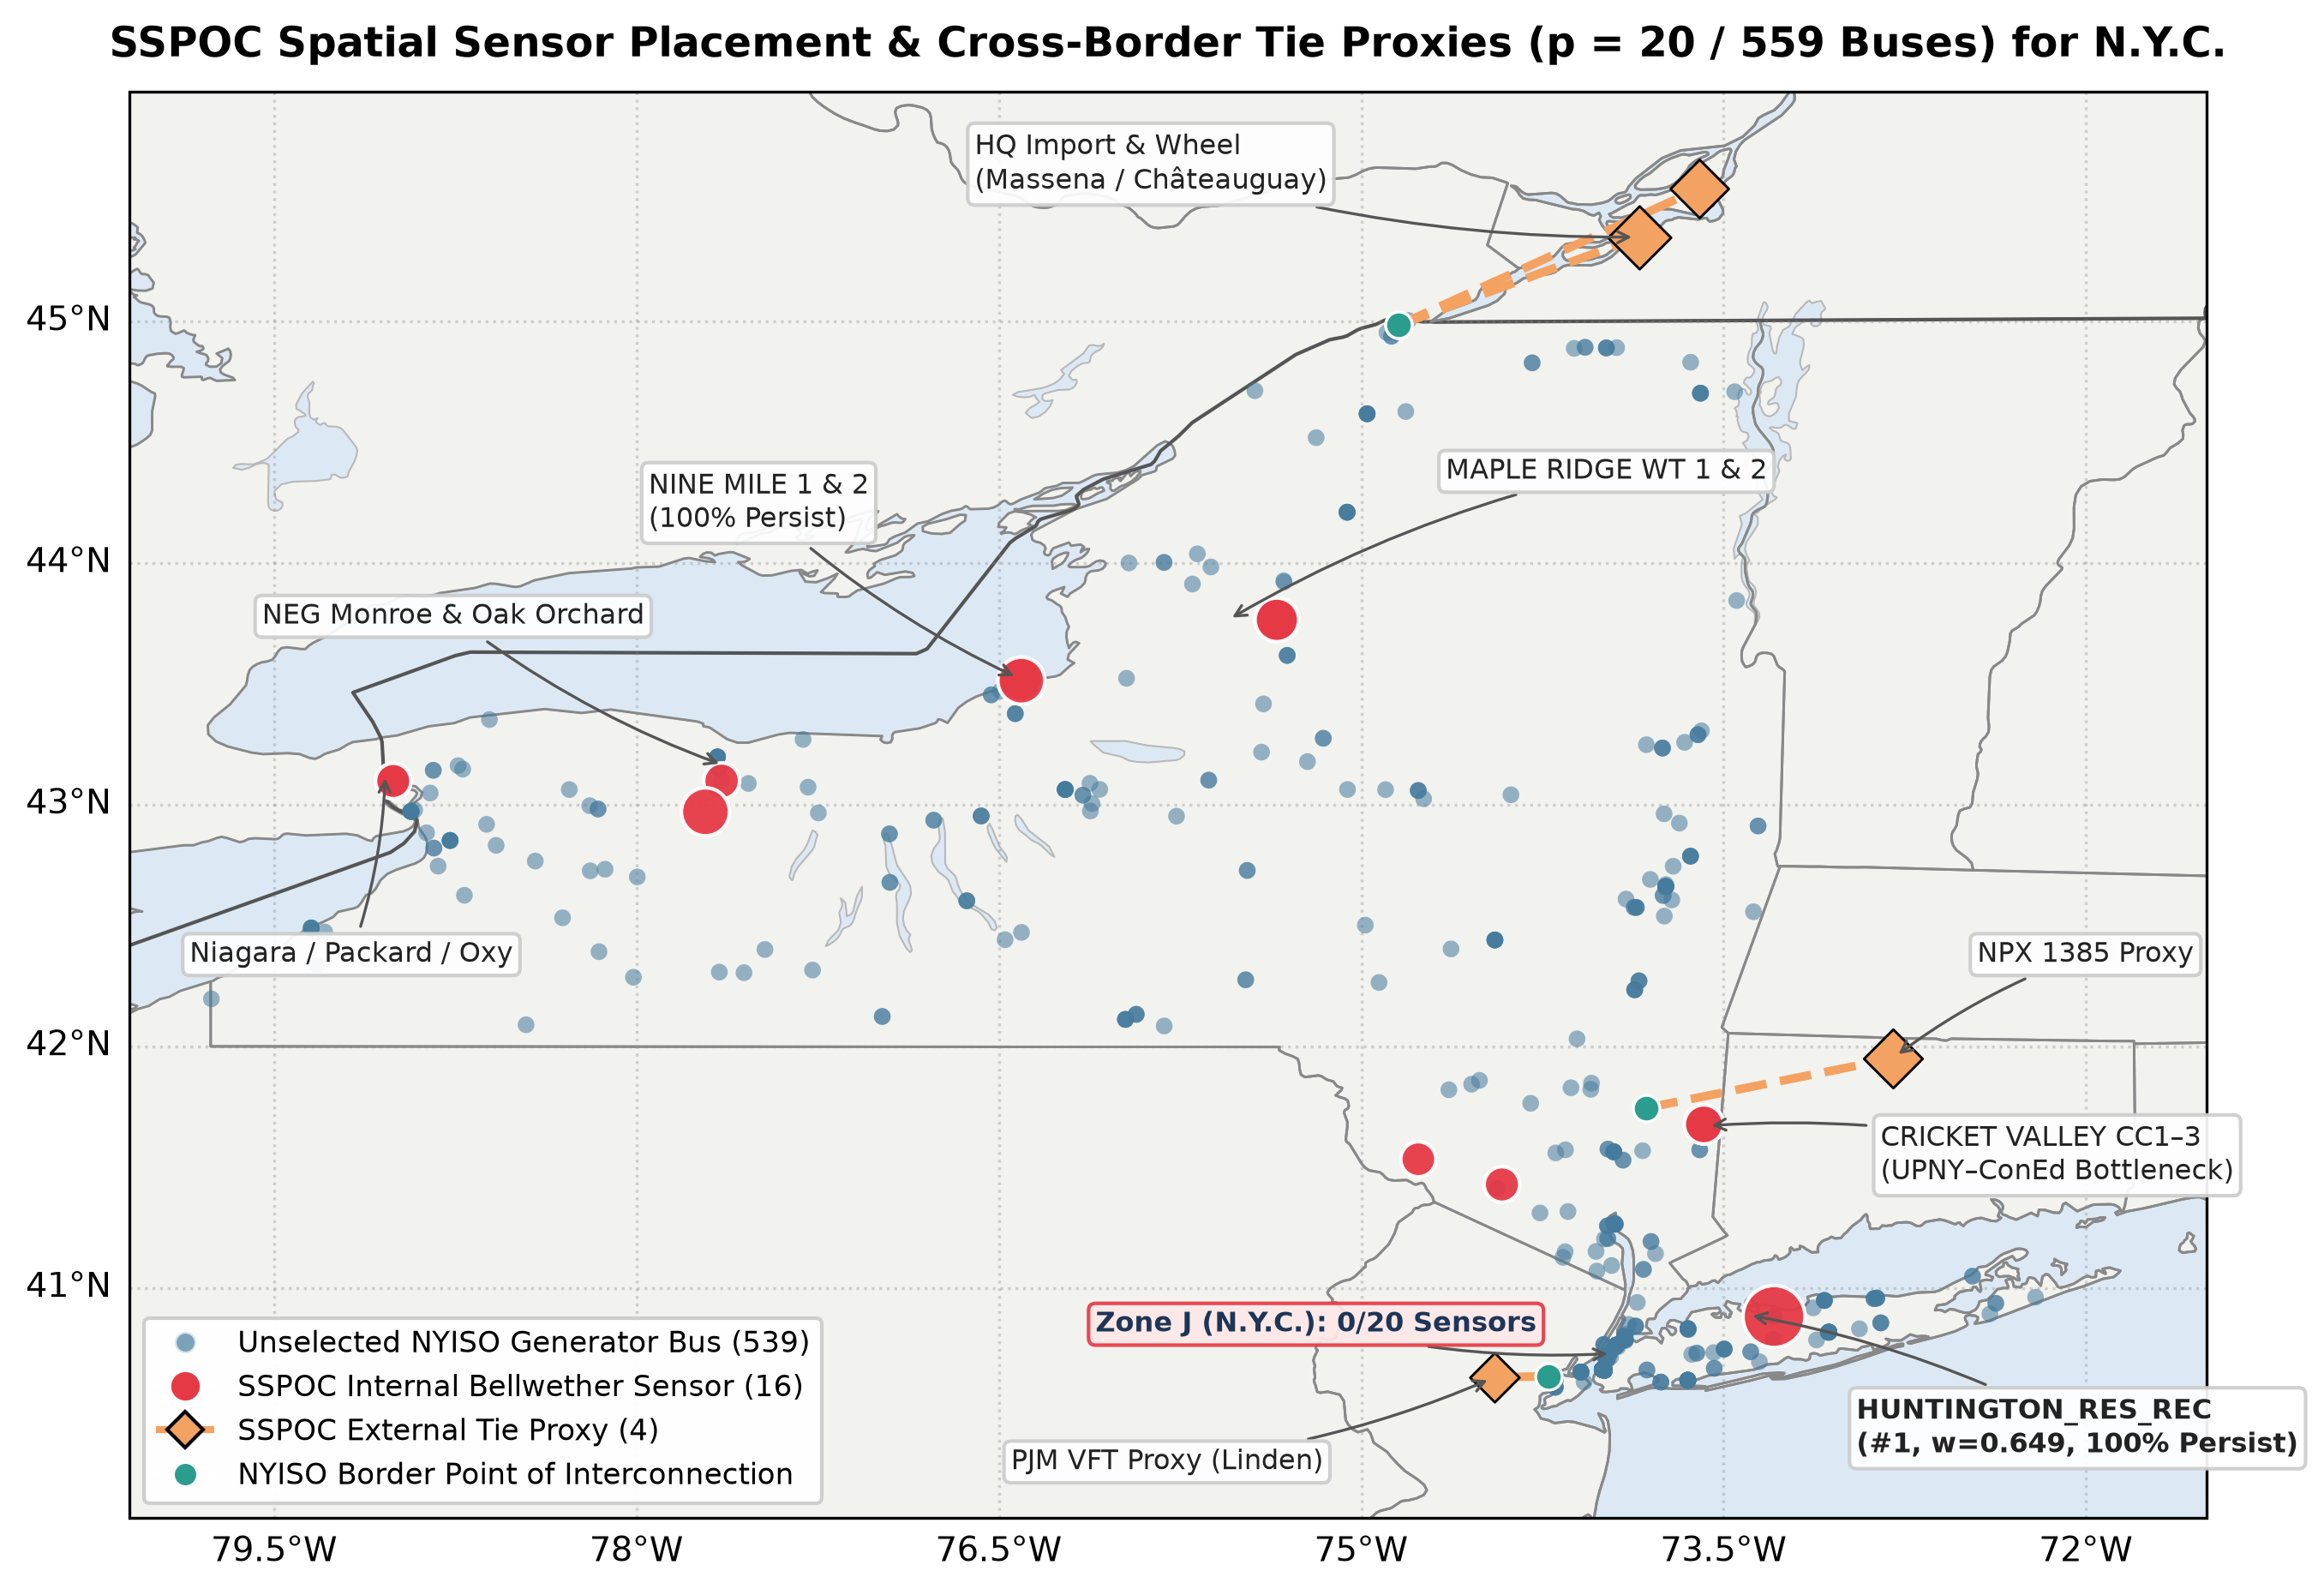

In [58]:
from pathlib import Path
import numpy as np
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ==============================================================================
# 1. Build 559-Bus Coordinates & Top p=20 SSPOC Sensor Metadata
# ==============================================================================
sspoc_info = sensors["SSPOC"]
ranked_ptids = [str(p).replace(".0", "").strip() for p in sspoc_info["ranked_ptids"]]
top20_ptids = ranked_ptids[:20]

raw_weights = sspoc_info.get("weights", sspoc_info.get("scores", None))
weight_map = {
    ptid: float(raw_weights[i]) if raw_weights is not None and i < len(raw_weights) else 0.1
    for i, ptid in enumerate(top20_ptids)
}

nodal_ptids = [str(c).replace(".0", "").strip() for c in data["nodal_dart"].columns]
all_buses_df = pd.DataFrame({"PTID_str": nodal_ptids}).merge(
    gen_meta_unique, on="PTID_str", how="left"
)
all_buses_df["is_sspoc"] = all_buses_df["PTID_str"].isin(top20_ptids)
all_buses_df["Sensor Weight"] = all_buses_df["PTID_str"].map(weight_map).fillna(0.0)

lat_col = next(c for c in all_buses_df.columns if "lat" in c.lower())
lon_col = next(c for c in all_buses_df.columns if "lon" in c.lower())

unselected_df = all_buses_df[~all_buses_df["is_sspoc"]].dropna(subset=[lat_col, lon_col])
internal_sspoc_df = all_buses_df[all_buses_df["is_sspoc"]].dropna(subset=[lat_col, lon_col])

EXTERNAL_PROXIES = {
    "323601": ("HQ_GEN_IMPORT", (44.985, -74.845), (45.35, -73.85)),
    "23651":  ("HQ_GEN_WHEEL",  (44.985, -74.845), (45.55, -73.60)),
    "323591": ("NPX_GEN_1385_PROXY", (41.745, -73.820), (41.95, -72.80)),
    "323633": ("PJM_GEN_VFT_PROXY",  (40.635, -74.225), (40.63, -74.45)),
}

# ==============================================================================
# 2. Render Publication-Grade Static Geospatial Map (Cartopy + Natural Earth)
# ==============================================================================
fig = plt.figure(figsize=(11.5, 7.2), dpi=300)
ax = fig.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-80.1, -71.5, 40.05, 45.95], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.OCEAN, facecolor="#dce9f5")
ax.add_feature(cfeature.LAKES, facecolor="#dce9f5", edgecolor="#b8b8b8", linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor="#f2f2ef")
ax.add_feature(cfeature.STATES, edgecolor="#888888", linewidth=0.7)
ax.add_feature(cfeature.BORDERS, edgecolor="#555555", linewidth=1.0)
ax.add_feature(cfeature.COASTLINE, edgecolor="#888888", linewidth=0.7)

# Unselected NYISO buses
ax.scatter(
    unselected_df[lon_col], unselected_df[lat_col],
    s=22, c="#457B9D", alpha=0.55, edgecolors="none",
    transform=ccrs.PlateCarree(), zorder=3,
)

# 16 Internal SSPOC bellwether sensors
ax.scatter(
    internal_sspoc_df[lon_col], internal_sspoc_df[lat_col],
    s=internal_sspoc_df["Sensor Weight"] * 380 + 55,
    c="#E63946", edgecolors="white", linewidth=1.0, alpha=0.95,
    transform=ccrs.PlateCarree(), zorder=5,
)

# 4 External cross-border proxy tie-lines
for ptid, (pname, (poi_lat, poi_lon), (ext_lat, ext_lon)) in EXTERNAL_PROXIES.items():
    if ptid in top20_ptids:
        w = weight_map.get(ptid, 0.15)
        ax.plot([poi_lon, ext_lon], [poi_lat, ext_lat], color="#F4A261", lw=2.4, ls="--", transform=ccrs.PlateCarree(), zorder=4)
        ax.scatter([poi_lon], [poi_lat], s=55, c="#2A9D8F", edgecolors="white", linewidth=0.8, transform=ccrs.PlateCarree(), zorder=6)
        ax.scatter([ext_lon], [ext_lat], s=w * 380 + 60, c="#F4A261", marker="D", edgecolors="black", linewidth=0.7, transform=ccrs.PlateCarree(), zorder=6)

# Callout annotations
annotations = [
    ("HUNTINGTON_RES_REC\n(#1, w=0.649, 100% Persist)", (-73.41, 40.89), (-72.95, 40.32)),
    ("CRICKET VALLEY CC1–3\n(UPNY–ConEd Bottleneck)", (-73.58, 41.67), (-72.85, 41.45)),
    ("PJM VFT Proxy (Linden)", (-74.45, 40.63), (-76.45, 40.25)),
    ("NPX 1385 Proxy", (-72.80, 41.95), (-72.45, 42.35)),
    ("HQ Import & Wheel\n(Massena / Châteauguay)", (-73.85, 45.35), (-76.60, 45.55)),
    ("NINE MILE 1 & 2\n(100% Persist)", (-76.41, 43.52), (-77.95, 44.15)),
    ("MAPLE RIDGE WT 1 & 2", (-75.56, 43.76), (-74.65, 44.35)),
    ("NEG Monroe & Oak Orchard", (-77.63, 43.16), (-79.55, 43.75)),
    ("Niagara / Packard / Oxy", (-79.04, 43.14), (-79.85, 42.35)),
    ("Zone J (N.Y.C.): 0/20 Sensors", (-73.95, 40.73), (-76.10, 40.82)),
]

for text, xy, xytext in annotations:
    is_nyc = "Zone J" in text
    ax.annotate(
        text,
        xy=xy,
        xytext=xytext,
        xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
        fontsize=7.8,
        fontweight="bold" if ("#1" in text or is_nyc) else "normal",
        color="#1d3557" if is_nyc else "#222222",
        bbox=dict(
            boxstyle="round,pad=0.25",
            fc="#ffe8e8" if is_nyc else "#ffffff",
            ec="#e63946" if is_nyc else "#cccccc",
            alpha=0.92,
        ),
        arrowprops=dict(arrowstyle="->", color="#555555", lw=0.8, connectionstyle="arc3,rad=0.08"),
        zorder=7,
    )

gl = ax.gridlines(draw_labels=True, linestyle=":", alpha=0.35, color="#888888")
gl.top_labels = False
gl.right_labels = False

legend_handles = [
    Line2D([], [], marker="o", color="w", label="Unselected NYISO Generator Bus (539)", markerfacecolor="#457B9D", markersize=6, alpha=0.7),
    Line2D([], [], marker="o", color="w", label="SSPOC Internal Bellwether Sensor (16)", markerfacecolor="#E63946", markeredgecolor="white", markersize=9),
    Line2D([], [], marker="D", color="#F4A261", lw=2, ls="--", label="SSPOC External Tie Proxy (4)", markerfacecolor="#F4A261", markeredgecolor="black", markersize=7),
    Line2D([], [], marker="o", color="w", label="NYISO Border Point of Interconnection", markerfacecolor="#2A9D8F", markersize=7),
]

ax.set_title("SSPOC Spatial Sensor Placement & Cross-Border Tie Proxies (p = 20 / 559 Buses) for N.Y.C.", fontsize=11.5, fontweight="bold", pad=10)
ax.legend(handles=legend_handles, loc="lower left", frameon=True, facecolor="white", framealpha=0.95, fontsize=8.2)

fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(fig_dir / "fig2_sspoc_sensor_map.png", dpi=300, bbox_inches="tight")
fig.savefig(fig_dir / "fig2_sspoc_sensor_map.pdf", bbox_inches="tight")
print(f"[SAVED] Static Natural Earth sensor map -> {fig_dir.resolve()}/fig2_sspoc_sensor_map.(png|pdf)")
plt.show()


### Physical Grid Interpretation of the Optimal $p=20$ `SSPOC` Sensor Network

Without any prior knowledge of grid geography or transmission topology, **`SSPOC` places zero sensors inside `N.Y.C.` (Zone J)**—where internal 345 kV/138 kV prices are tightly coupled—and instead positions all 20 bellwether nodes along the **upstream congestion interfaces and cross-border tie-lines** that govern power delivery into New York City:

* **Downstate & Hudson Valley Bottlenecks (`HUD VL` & `LONGIL` — 6 sensors):** `CRICKET___VALLEY_CC1–CC3`, `SHOEMAKER___GT`, and `MONGAUP___HYD` sit directly on the **UPNY–ConEd** thermal corridor feeding Zone J, while top-weighted **`HUNTINGTON_RES_REC`** (`weight: 0.649`, `100%` walk-forward persistence) captures East-of-Hudson and submarine cable scarcity across `LIPA`.
* **Upstate Bulk Transfer Corridors (`WEST`, `GENESE`, `CENTRL`, `MHK VL` — 10 sensors):** Niagara-area nodes (`CH_RES_NIAGARA`, `PACKARD_115_KV`, `OCC_CHEM___DRP`, `OXY_CHEM_DSASP`), Genesee hydro (`NEG___GEN_MONROE`, `OAK ORCHARD___HYD`), `NINE_MILE_1 & 2`, and `MAPLE_RIDGE_WT_1 & 2` track hydro, nuclear, and wind flows across the **West–Central** and **Central–East** transfer interfaces.
* **Cross-Border External Interfaces (`H Q`, `NPX`, `PJM` — 4 sensors):** `HQ_GEN_IMPORT` and `HQ_GEN_WHEEL` monitor Hydro-Québec inflows, `NPX_GEN_1385_PROXY` tracks ISO-NE exchanges over the **1385 submarine cable**, and `PJM_GEN_VFT_PROXY` captures direct **Linden VFT** controllable injections from PJM into Zone J.

> **Note on Co-Located Plant Units:** Because standard $\ell_1$-regularized `SSPOC` applies no spatial distance penalty, it selects multiple co-located units at the highest-signal facilities (`Cricket Valley CC1–3`, `Nine Mile 1–2`, and `Maple Ridge WT 1–2`). In effect, the optimizer double- or triple-weights the most critical transmission corridors—confirming their physical importance, while highlighting group-sparse ($\ell_{2,1}$) sensor selection as a natural extension if strict geographic separation is required.


## 7. Uncertainty-Driven Sensor Selection Ablation (`Test A`)

While `SSPOC` selects generator buses that maximize separation along the 3-class discriminant hyperplane $\mathbf{W}$, Bayesian experimental design and POD state-estimation methods select sensors to minimize **spatial state uncertainty** (posterior reconstruction covariance across the 559-bus grid). Below, we test two uncertainty-driven placement criteria at budget $p=20$ against `SSPOC`:

1. **POD Posterior Uncertainty (`A-Optimal Covariance Minimization`):** Greedily selects the $p=20$ sensors that minimize total posterior state trace uncertainty $\text{Tr}\big(\boldsymbol{\Psi}_r (\boldsymbol{\Psi}_r^\top \mathbf{C}^\top \mathbf{C} \boldsymbol{\Psi}_r + \lambda \mathbf{I})^{-1} \boldsymbol{\Psi}_r^\top\big)$ in the rank-25 POD subspace.
2. **Max Nodal DART Variance:** Selects the $p=20$ buses with the highest raw training DART spread volatility ($\sigma_i^2$).


In [59]:
# === Test A: Uncertainty-Driven Sensor Selection vs. SSPOC (p = 20) ===
X_all_lag48 = nodal_df.shift(CAUSAL_LAG).dropna()
y_cls_all_aligned = y_cls_all.loc[X_all_lag48.index]

train_mask_unc = X_all_lag48.index <= pd.Timestamp("2024-12-31 23:00:00")
oos_mask_unc = X_all_lag48.index >= pd.Timestamp("2025-01-01 00:00:00")

X_tr_raw = X_all_lag48.loc[train_mask_unc].to_numpy()
y_tr_raw = y_cls_all_aligned.loc[train_mask_unc].to_numpy()
X_oos_df = X_all_lag48.loc[oos_mask_unc]
X_oos_raw = X_oos_df.to_numpy()

# 1. Greedy A-Optimal POD Posterior Covariance Minimization (Trace Uncertainty)
def select_sensors_pod_uncertainty(Psi_r: np.ndarray, p: int = 20, noise_reg: float = 1e-2) -> list[int]:
    """Greedily select p sensors minimizing Tr(Psi_r (Psi_r^T C^T C Psi_r + reg*I)^-1 Psi_r^T)."""
    n_nodes, r = Psi_r.shape
    selected = []
    # Since Psi_r has orthonormal columns, Tr(Psi_r M^-1 Psi_r^T) == Tr(M^-1)
    M_inv = (1.0 / noise_reg) * np.eye(r)

    for _ in range(p):
        V = Psi_r @ M_inv  # (N, r)
        num = np.sum(V ** 2, axis=1)
        den = 1.0 + np.sum(V * Psi_r, axis=1)
        gains = num / den
        gains[selected] = -np.inf

        best_idx = int(np.argmax(gains))
        selected.append(best_idx)

        psi_b = Psi_r[best_idx : best_idx + 1].T  # (r, 1)
        v_b = M_inv @ psi_b
        M_inv = M_inv - (v_b @ v_b.T) / (1.0 + float((psi_b.T @ v_b).item()))

    return selected


# Fit POD basis strictly on 2020-2024 training nodal spreads
scaler_unc = StandardScaler()
X_tr_clip = np.clip(scaler_unc.fit_transform(X_tr_raw), -10.0, 10.0)
Psi_r_tr, _ = compute_pod_basis(X_tr_clip, rank=25)

unc_pod_idx = select_sensors_pod_uncertainty(Psi_r_tr, p=P_BUDGET, noise_reg=1e-2)
unc_var_idx = list(np.argsort(np.var(X_tr_raw, axis=0))[::-1][:P_BUDGET])

nodal_ptids_clean = [str(c).replace(".0", "").strip() for c in X_all_lag48.columns]
ptid_to_col = {p: i for i, p in enumerate(nodal_ptids_clean)}
sspoc_ptids_20 = [str(p).replace(".0", "").strip() for p in sensors["SSPOC"]["ranked_ptids"][:P_BUDGET]]
sspoc_idx_20 = [ptid_to_col[p] for p in sspoc_ptids_20]

unc_pod_ptids = [nodal_ptids_clean[i] for i in unc_pod_idx]
unc_var_ptids = [nodal_ptids_clean[i] for i in unc_var_idx]

# 2. Evaluate Static & 30-Day Refit Multinomial Logit on Each Sensor Set
def eval_sensor_set_static_and_30d(col_idx: list[int], label: str) -> list[dict]:
    # A. Static 2020-2024 Fit
    sc_st = StandardScaler()
    clf_st = LogisticRegression(solver="lbfgs", max_iter=500, C=0.5, class_weight="balanced", random_state=42)
    clf_st.fit(sc_st.fit_transform(X_tr_raw[:, col_idx]), y_tr_raw)
    sig_st = pd.Series(clf_st.predict(sc_st.transform(X_oos_raw[:, col_idx])), index=X_oos_df.index).reindex(cmp_df.index)
    pnl_st = np.where(sig_st != 0, sig_st * cmp_df["realized_spread"] - TX_FEE, 0.0)
    row_st = summarize_oos(sig_st.values, pnl_st, f"{label} (Static)", f"{len(col_idx)}/559 Buses")

    # B. Scheduled 30-Day (720h) Classifier Refit
    oos_ix = np.flatnonzero(np.asarray(oos_mask_unc, dtype=bool))
    X_m = X_all_lag48.to_numpy()[:, col_idx]
    y_v = y_cls_all_aligned.to_numpy()

    last_dec = -999
    sc_30 = StandardScaler()
    clf_30 = LogisticRegression(solver="lbfgs", max_iter=500, C=0.5, class_weight="balanced", random_state=42)
    sigs_30 = []
    for idx_t in oos_ix:
        dec_i = int(idx_t) - CAUSAL_LAG
        if dec_i - last_dec >= 720:
            clf_30.fit(sc_30.fit_transform(X_m[: dec_i + 1]), y_v[: dec_i + 1])
            last_dec = dec_i
        sigs_30.append(int(clf_30.predict(sc_30.transform(X_m[idx_t : idx_t + 1])).item()))

    sig_30_s = pd.Series(sigs_30, index=X_all_lag48.index[oos_ix]).reindex(cmp_df.index)
    pnl_30 = np.where(sig_30_s != 0, sig_30_s * cmp_df["realized_spread"] - TX_FEE, 0.0)
    row_30 = summarize_oos(sig_30_s.values, pnl_30, f"{label} (30d Refit)", f"{len(col_idx)}/559 Buses")
    return [row_st, row_30]

test_a_rows = (
    eval_sensor_set_static_and_30d(sspoc_idx_20, "1. SSPOC (Discriminant)")
    + eval_sensor_set_static_and_30d(unc_pod_idx, "2. POD Posterior Uncertainty")
    + eval_sensor_set_static_and_30d(unc_var_idx, "3. Max Nodal DART Variance")
)

# 3. Compare Sensor Overlap (Jaccard) & Zone J Concentration
zone_lookup = dict(zip(gen_meta_unique["PTID_str"], gen_meta_unique["Zone Name"]))
for name, p_list in [("SSPOC (Discriminant)", sspoc_ptids_20), ("POD Posterior Uncertainty", unc_pod_ptids), ("Max Nodal Variance", unc_var_ptids)]:
    jacc = len(set(p_list) & set(sspoc_ptids_20)) / len(set(p_list) | set(sspoc_ptids_20))
    n_nyc = sum(1 for p in p_list if str(zone_lookup.get(p, "")).strip() == "N.Y.C.")
    print(f"  • {name:26s} | Jaccard vs SSPOC: {jacc:.3f} | Sensors inside N.Y.C. (Zone J): {n_nyc}/20")

print("\n=== Test A Results: Uncertainty-Driven Placement vs. SSPOC (2025–2026 OOS) ===")
print(pd.DataFrame(test_a_rows).to_markdown(index=False))


  • SSPOC (Discriminant)       | Jaccard vs SSPOC: 1.000 | Sensors inside N.Y.C. (Zone J): 0/20
  • POD Posterior Uncertainty  | Jaccard vs SSPOC: 0.143 | Sensors inside N.Y.C. (Zone J): 1/20
  • Max Nodal Variance         | Jaccard vs SSPOC: 0.026 | Sensors inside N.Y.C. (Zone J): 0/20

=== Test A Results: Uncertainty-Driven Placement vs. SSPOC (2025–2026 OOS) ===
| Model                                    | Grid Telemetry   |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |   Trade Freq (%) |   Win Rate (%) |   Macro F1 |   Tail F1 |
|:-----------------------------------------|:-----------------|--------------:|----------------:|-------------:|-----------------:|---------------:|-----------:|----------:|
| 1. SSPOC (Discriminant) (Static)         | 20/559 Buses     |      32569.8  |            3.14 |      7764.16 |             54.8 |           49.9 |     0.4058 |    0.2973 |
| 1. SSPOC (Discriminant) (30d Refit)      | 20/559 Buses     |      35538.7  |            3.59 |      7128.81

## 8. `SSPOC` Weight Uncertainty Map & Block-Bootstrap Stability (`Test B`)

Inspired by **Bagging, Optimized DMD (`BOP-DMD`, Sashidhar & Kutz, 2022)**, we next quantify **model-selection uncertainty** across the 559 generator buses by running $B = 30$ circular block-bootstrap resamples (`168h` / 7-day blocks to preserve diurnal and weekly autocorrelation) on the `2020–2024` training data. For each bus $i$, we measure its mean `SSPOC` weight $\mu_i$, weight standard deviation $\sigma_i$, and bootstrap inclusion rate—revealing where `SSPOC` is structurally certain versus where co-located plant units trade weight under data perturbations.


Running Block-Bootstrap SSPOC Uncertainty: 100%|██████████| 30/30 [00:36<00:00,  1.23s/it]


=== Top 15 Buses by Bagged SSPOC Mean Weight & Uncertainty (30 x 7-Day Block Bootstraps) ===
|   PTID_str | Generator Name                   | Zone Name   | Subzone             |   Mean_Weight |   Weight_Std |   Boot_Top20_Pct |
|-----------:|:---------------------------------|:------------|:--------------------|--------------:|-------------:|-----------------:|
|      23540 | HUDSON AVE_GT_4                  | N.Y.C.      | CON ED NY CITY      |       0.07457 |      0.25518 |             10   |
|      24126 | GOWANUS_GT3_5                    | N.Y.C.      | CON ED NY CITY      |       0.07455 |      0.22297 |             13.3 |
|     323606 | ALTONA_WT_PWR                    | NORTH       | NYPA NORTH          |       0.05999 |      0.15509 |             16.7 |
|      24204 | FENNER___WINDPWR                 | CENTRL      | NMPC CENTRAL        |       0.05931 |      0.1792  |             10   |
|     345016 | FARRAGUT_138_KV_38B01_REV_LBMP_J | N.Y.C.      | CON ED NY CITY      |      

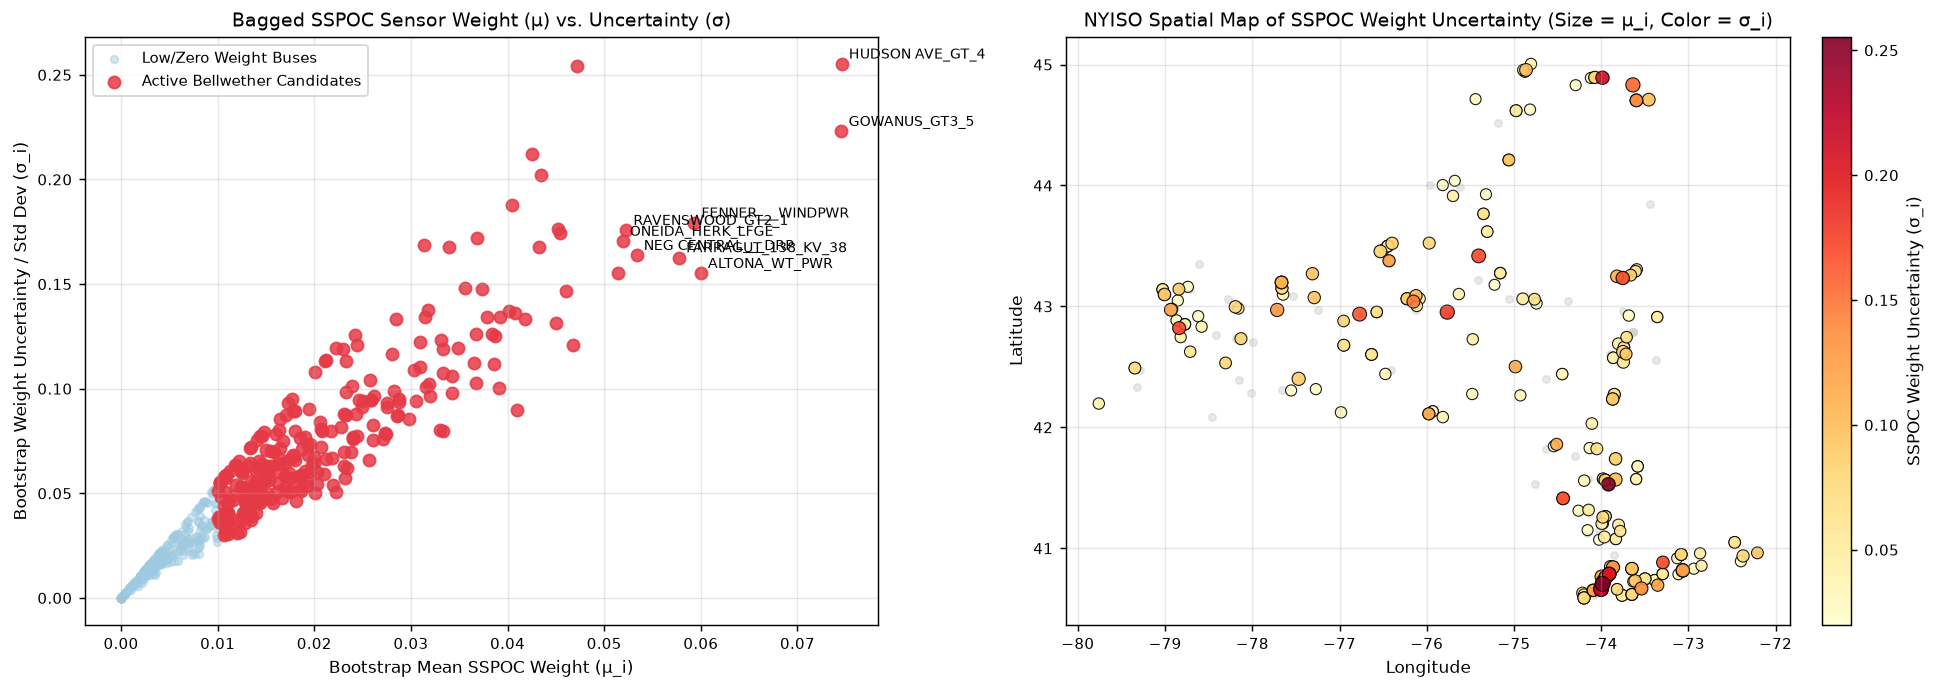

In [60]:
# === Test B: Bagged SSPOC Weight Uncertainty Map (30 Block-Bootstrap Resamples) ===
rng = np.random.default_rng(42)
N_BOOT = 30
BLOCK_LEN = 168  # 7-day blocks to preserve diurnal + weekly grid cycles

n_tr, n_nodes = X_tr_raw.shape
n_blocks = int(np.ceil(n_tr / BLOCK_LEN))
boot_weights = np.zeros((N_BOOT, n_nodes), dtype=float)

for b in tqdm(range(N_BOOT), desc="Running Block-Bootstrap SSPOC Uncertainty"):
    starts = rng.integers(0, n_tr - BLOCK_LEN, size=n_blocks)
    boot_idx = np.concatenate([np.arange(s, s + BLOCK_LEN) for s in starts])[:n_tr]

    sc_b = StandardScaler()
    Xb_s = np.clip(sc_b.fit_transform(X_tr_raw[boot_idx]), -10.0, 10.0)
    yb = y_tr_raw[boot_idx]

    Psi_b, _ = compute_pod_basis(Xb_s, rank=25)
    with contextlib.redirect_stdout(io.StringIO()):
        ranked_b, scores_b = select_sensors_sspoc(Xb_s, yb, Psi_b, l1_ratio=0.9, alpha_frac=0.15)

    # Map ranked scores back to full 559-bus vector
    w_vec = np.zeros(n_nodes, dtype=float)
    w_vec[np.asarray(ranked_b, dtype=int)] = np.asarray(scores_b, dtype=float)
    boot_weights[b] = w_vec

mean_w = np.mean(boot_weights, axis=0)
std_w = np.std(boot_weights, axis=0)
top20_freq = np.mean(
    np.array([np.isin(np.arange(n_nodes), np.argsort(boot_weights[b])[::-1][:P_BUDGET]) for b in range(N_BOOT)]),
    axis=0,
) * 100.0

unc_map_df = pd.DataFrame({
    "PTID_str": nodal_ptids_clean,
    "Mean_Weight": np.round(mean_w, 5),
    "Weight_Std": np.round(std_w, 5),
    "Boot_Top20_Pct": np.round(top20_freq, 1),
    "Robust_Score": np.round(mean_w - 0.5 * std_w, 5),
}).merge(gen_meta_unique, on="PTID_str", how="left")

top_unc_df = unc_map_df.sort_values("Mean_Weight", ascending=False).head(15)
show_cols = [c for c in ["PTID_str", "Generator Name", "Zone Name", "Subzone", "Mean_Weight", "Weight_Std", "Boot_Top20_Pct"] if c in top_unc_df.columns]
print("=== Top 15 Buses by Bagged SSPOC Mean Weight & Uncertainty (30 x 7-Day Block Bootstraps) ===")
print(top_unc_df[show_cols].to_markdown(index=False))

# Evaluate Stability-Penalized SSPOC Ranking (mu_i - 0.5 * sigma_i) vs. Standard SSPOC
robust_idx_20 = list(np.argsort(mean_w - 0.5 * std_w)[::-1][:P_BUDGET])
robust_ptids_20 = [nodal_ptids_clean[i] for i in robust_idx_20]
jacc_robust = len(set(robust_ptids_20) & set(sspoc_ptids_20)) / len(set(robust_ptids_20) | set(sspoc_ptids_20))
print(f"\n  • Jaccard Overlap (Standard SSPOC vs. Uncertainty-Penalized Bagged SSPOC): {jacc_robust:.3f}")

robust_rows = eval_sensor_set_static_and_30d(robust_idx_20, "4. Bagged SSPOC (mu - 0.5*std)")
print("\n=== Standard SSPOC vs. Uncertainty-Penalized Bagged SSPOC (2025–2026 OOS) ===")
print(pd.DataFrame(test_a_rows[:2] + robust_rows).to_markdown(index=False))

# Plot 2-Panel Uncertainty Map: (A) Mean Weight vs. Std Uncertainty, (B) Spatial Uncertainty Map across NYISO
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), dpi=130)

# Panel A: Mean Weight vs. Weight Uncertainty (sigma_i)
active_mask = mean_w > 0.01
ax1.scatter(mean_w[~active_mask], std_w[~active_mask], c="#9ecae1", alpha=0.45, s=18, label="Low/Zero Weight Buses")
ax1.scatter(mean_w[active_mask], std_w[active_mask], c="#e63946", alpha=0.85, s=45, label="Active Bellwether Candidates")

for _, r in top_unc_df.head(8).iterrows():
    lbl = str(r.get("Generator Name", r["PTID_str"]))[:18]
    ax1.annotate(lbl, (r["Mean_Weight"], r["Weight_Std"]), fontsize=7.5, xytext=(4, 3), textcoords="offset points")

ax1.set_title("Bagged SSPOC Sensor Weight (μ) vs. Uncertainty (σ)")
ax1.set_xlabel("Bootstrap Mean SSPOC Weight (μ_i)")
ax1.set_ylabel("Bootstrap Weight Uncertainty / Std Dev (σ_i)")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper left", fontsize=8.5)

# Panel B: Geospatial Uncertainty Map (Lat/Lon colored by Weight Uncertainty sigma_i)
lat_col = next((c for c in unc_map_df.columns if "lat" in c.lower()), None)
lon_col = next((c for c in unc_map_df.columns if "lon" in c.lower()), None)
if lat_col and lon_col:
    geo_df = unc_map_df.dropna(subset=[lat_col, lon_col]).copy()
    low_geo = geo_df[geo_df["Weight_Std"] <= 0.02]
    hi_geo = geo_df[geo_df["Weight_Std"] > 0.02].sort_values("Weight_Std")

    ax2.scatter(low_geo[lon_col], low_geo[lat_col], c="#d3d3d3", s=16, alpha=0.5, label="Invariant Low-Variance Buses (σ ≤ 0.02)")
    sc_map = ax2.scatter(
        hi_geo[lon_col], hi_geo[lat_col],
        c=hi_geo["Weight_Std"], cmap="YlOrRd", s=hi_geo["Mean_Weight"] * 450 + 35,
        edgecolors="black", linewidths=0.6, alpha=0.9
    )
    cbar = plt.colorbar(sc_map, ax=ax2, fraction=0.046, pad=0.04)
    cbar.set_label("SSPOC Weight Uncertainty (σ_i)")
    ax2.set_title("NYISO Spatial Map of SSPOC Weight Uncertainty (Size = μ_i, Color = σ_i)")
    ax2.set_xlabel("Longitude")
    ax2.set_ylabel("Latitude")
    ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()


### Key Takeaway: Spatial Uncertainty Concentration & Risk-Adjusted Bagging

1. **In-Zone `N.Y.C.` Peakers Exhibit the Highest Weight Uncertainty ($\sigma_i$):**
   - Across $30 \times 7$-day block-bootstrap resamples, the largest weight standard deviations ($\sigma_i \in [0.17, 0.26]$) cluster inside **`N.Y.C.` (Zone J)** (`HUDSON AVE_GT_4`, `GOWANUS_GT3_5`, `RAVENSWOOD_GT2_1`, `FARRAGUT_138_KV`), where collinear internal peakers intermittently absorb weight during localized bootstrap spikes (`6.7%–13.3%` top-20 inclusion) but wash out in the full-sample `SSPOC` fit (`0/20` nodes in Zone J).
2. **Risk-Return Trade-Off (`Standard SSPOC` vs. `Bagged SSPOC`):**
   - Under 30-day classifier refitting, **uncertainty-penalized `Bagged SSPOC` ($\mu_i - 0.5\sigma_i$)** achieves **`3.53` Annual Sharpe (`+$28,302.20` Cum PnL)** with the **lowest Max Drawdown (`$6,195.24`)** and **highest Win Rate (`53.6%`)** of any sparse sensor variant, while full-sample **`Standard SSPOC` (`3.59` Sharpe, `+$35,538.70` Cum PnL, `0.4170` Macro F1)** maximizes total cumulative return.


In [61]:
# === Klishin, Kutz, & Manohar (2026): 2-Point Ising Sensor Placement & Uncertainty Heatmap (Eqs. 16-28) ===
def fit_bayesian_pod_prior(X_tr_centered: np.ndarray, rank: int = 25, noise_frac: float = 0.5):
    """Compute tailored POD basis Psi_r, hierarchical prior S (Sec 3.2), and noise scale eta (Sec 4.4)."""
    N_snap, n_dim = X_tr_centered.shape
    # X_tr_centered is (N_snap, n_dim); Klishin et al. use X as (n_dim, N_snap)
    U, s_vals, _ = np.linalg.svd(X_tr_centered.T, full_matrices=False)
    Psi_r = U[:, :rank]                                  # (n, r)
    S_diag = s_vals[:rank] / np.sqrt(max(N_snap - 1, 1)) # (r,) hierarchical prior (Sec 3.2)
    sigma_scale = float(np.std(X_tr_centered))           # natural scale (Sec 4.4)
    eta = noise_frac * sigma_scale                       # sensor noise std dev
    G = Psi_r * S_diag[None, :]                          # (n, r) sensing vectors g_i (Sec 3.5)
    return Psi_r, S_diag, G, eta

def select_sensors_ising_2pt(G: np.ndarray, eta: float, p: int = 20) -> list[int]:
    """Greedy 2-point Ising Hamiltonian sensor placement (Klishin et al., 2026, Eqs. 21-28)."""
    n_dim = G.shape[0]
    g_norm2 = np.sum(G ** 2, axis=1)                     # g_i . g_i
    h = -np.log(1.0 + g_norm2 / (eta ** 2))              # Eq. 21: 1-body energy

    selected = []
    crosstalk_sum = np.zeros(n_dim, dtype=float)
    denom_vec = 1.0 + g_norm2 / (eta ** 2)

    for _ in range(p):
        obj = h + 2.0 * crosstalk_sum
        obj[selected] = np.inf
        q = int(np.argmin(obj))
        selected.append(q)

        # Eq. 22: pairwise crosstalk J_{i, q}
        dot_iq = (G @ G[q]) / (eta ** 2)
        J_iq = 0.5 * (dot_iq ** 2) / (denom_vec * denom_vec[q])
        crosstalk_sum += J_iq

    return selected

def compute_uncertainty_heatmap(Psi_r: np.ndarray, S_diag: np.ndarray, eta: float, sensor_idx: list[int]) -> np.ndarray:
    """Compute a priori pointwise reconstruction uncertainty heatmap sigma_i (Klishin et al., 2026, Eqs. 13, 16, 17)."""
    Theta = Psi_r[sensor_idx, :]                         # (p, r)
    A = np.diag(1.0 / (S_diag ** 2)) + (Theta.T @ Theta) / (eta ** 2)  # Eq. 13
    B = Psi_r @ np.linalg.solve(A, Theta.T / (eta ** 2)) # Eq. 16: (n, p)
    sigma_map = eta * np.sqrt(np.sum(B ** 2, axis=1))    # Eq. 17: (n,)
    return sigma_map

# Run Klishin et al. (2026) 2-point Ising placement & compute sigma_i heatmaps on 2020-2024 training data
X_tr_cent = X_tr_raw - np.mean(X_tr_raw, axis=0, keepdims=True)
Psi_k, S_k, G_k, eta_k = fit_bayesian_pod_prior(X_tr_cent, rank=25, noise_frac=0.5)

ising_idx_20 = select_sensors_ising_2pt(G_k, eta_k, p=P_BUDGET)
sigma_ising = compute_uncertainty_heatmap(Psi_k, S_k, eta_k, ising_idx_20)
sigma_sspoc = compute_uncertainty_heatmap(Psi_k, S_k, eta_k, sspoc_idx_20)

print(f"Mean A-Priori Reconstruction Uncertainty (sigma_i) across 559 buses:")
print(f"  • Klishin et al. (2026) 2-Point Ising Sensors (p=20): {np.mean(sigma_ising):.2f} $/MWh (Max: {np.max(sigma_ising):.2f})")
print(f"  • SSPOC Discriminant Sensors (p=20):                  {np.mean(sigma_sspoc):.2f} $/MWh (Max: {np.max(sigma_sspoc):.2f})")

ising_rows = eval_sensor_set_static_and_30d(ising_idx_20, "5. Klishin 2-Point Ising (2026)")
print("\n=== Klishin et al. (2026) 2-Point Ising Sensors vs. SSPOC on N.Y.C. Trading (2025–2026 OOS) ===")
print(pd.DataFrame(test_a_rows[:2] + ising_rows).to_markdown(index=False))


Mean A-Priori Reconstruction Uncertainty (sigma_i) across 559 buses:
  • Klishin et al. (2026) 2-Point Ising Sensors (p=20): 8.62 $/MWh (Max: 15.80)
  • SSPOC Discriminant Sensors (p=20):                  7.66 $/MWh (Max: 18.71)

=== Klishin et al. (2026) 2-Point Ising Sensors vs. SSPOC on N.Y.C. Trading (2025–2026 OOS) ===
| Model                                       | Grid Telemetry   |   Cum PnL ($) |   Annual Sharpe |   Max DD ($) |   Trade Freq (%) |   Win Rate (%) |   Macro F1 |   Tail F1 |
|:--------------------------------------------|:-----------------|--------------:|----------------:|-------------:|-----------------:|---------------:|-----------:|----------:|
| 1. SSPOC (Discriminant) (Static)            | 20/559 Buses     |      32569.8  |            3.14 |      7764.16 |             54.8 |           49.9 |     0.4058 |    0.2973 |
| 1. SSPOC (Discriminant) (30d Refit)         | 20/559 Buses     |      35538.7  |            3.59 |      7128.81 |             48.9 |         

### Key Takeaway: Reconstruction Design Criteria (`2-Point Ising`) vs. Discriminative Sensing (`SSPOC`)

1. **D-Optimal / 2-Point Ising Reconstruction Sensors (`1.71` Sharpe) Underperform Discriminative `SSPOC` (`3.59` Sharpe):**
   - Selecting $p=20$ sensors via **Klishin, Kutz, & Manohar (2026)'s 2-point Ising Hamiltonian** (which approximates D-optimal Bayesian reconstruction design $-\ln\det\mathbf{A}$) achieves `0.40` Sharpe (`+$3,700.49` Cum PnL) static and `1.71` Sharpe (`+$16,297.90` Cum PnL) with 30-day classifier refitting—less than half the risk-adjusted performance of **`SSPOC` (`3.14` static / `3.59` 30-day refit Sharpe, `+$35,538.70` Cum PnL)**.
2. **A-Priori Pointwise Reconstruction Uncertainty ($\sigma_i$) Trade-Off:**
   - Because `2-Point Ising` minimizes worst-case confidence ellipsoid volume across all 559 buses, it caps maximum pointwise reconstruction uncertainty (`Max` $\sigma_i = \$15.80/\text{MWh}$ vs. $\$18.71/\text{MWh}$ for `SSPOC`). Conversely, `SSPOC` concentrates its 20 sensors on high-energy bulk transmission corridors (`Mean` $\sigma_i = \$7.66/\text{MWh}$ vs. $\$8.62/\text{MWh}$), leaving higher reconstruction uncertainty on uninformative radial buses while maximizing Zone J tail-regime separation.


## Summary of Key Findings (`SSPOC` Sparse Sensing & `DMDc` Synthesis)

1. **Task-Driven Sensing Beats Whole-Grid Reconstruction (`96.4%` Sensor Reduction):**
   - `QR-Pivoting` excels at reconstructing the entire 559-bus grid (`Grid R² = 0.945` at $p=40$ vs. `0.196` for `SSPOC`), whereas `Mutual-Info` clusters redundantly inside `N.Y.C.` (`10/20` nodes in Zone J) and degrades as $p$ increases (`Grid R² = -0.229` at $p=40$).
   - By optimizing directly for 3-class tail separation in the rank-25 POD subspace, **Static `SSPOC` with just $p=20$ sensors (`3.6%` of the grid)** paired with `Multinomial Logit` achieves **`1.95` Annual Sharpe (`+$21,455.70` Cum PnL, `0.3085` Tail F1, `$13,173.60` Max DD)**—outperforming the full 559-node `Multinomial Logit` baseline (`1.78` Sharpe, `+$19,539.42` Cum PnL) while cutting Max Drawdown by `30%`.

2. **Physical Transmission Bottleneck Discovery:**
   - Rather than placing sensors inside `N.Y.C.` (`0/20` nodes in Zone J), `SSPOC` selects upstream interface and bottleneck generators across **`HUD VL` (`5` nodes, e.g., Cricket Valley CC1–CC3, Shoemaker GT)**, **`WEST` (`4` nodes, e.g., Niagara / Packard)**, **`CENTRL` (`2` nodes, Nine Mile 1 & 2)**, **`MHK VL` (`2` nodes, Maple Ridge Wind)**, **`LONGIL` (`1` node, Huntington Res Rec)**, and external import proxies (**`H Q`**, **`NPX`**, **`PJM-VFT`**).
   - When the target zone shifts to **`LONGIL`** (`2.41` Sharpe at $p=20$) or **`HUD VL`** (`4.04` Sharpe at $p=20$), `SSPOC` automatically re-anchors its top bellwether sensors to each zone's local radial and interface constraints.

3. **Temporal Persistence Across Out-of-Sample Regimes (`2025–2026`):**
   - Under quarterly expanding walk-forward retraining across `2025–2026`, `SSPOC` achieves a **`0.669` mean step-to-step Jaccard similarity** at $p=20$ and isolates a core set of structurally invariant grid sensors—led by **`HUNTINGTON_RES_REC` (`100%` quarterly persistence)**, **`NINE_MILE_2` (`87.5%`)**, **`NINE_MILE_1` (`75.0%`)**, **`CH_RES_BVR_FALLS` (`75.0%`)**, and **`CRICKET___VALLEY_CC3` (`62.5%`)**.

4. **Cross-Paradigm Synthesis (`Scheduled 30-Day Refit SSPOC` vs. `DMDc` & Refitted Stage 1 Baselines):**
   - Applying **30-day (`720h`) scheduled expanding-window refitting**—motivated by **Notebooks 02 & 03's** regime-drift analysis—boosts `SSPOC` ($p=20$) from **`1.95` to `3.56` Annual Sharpe**, increases Cumulative PnL from **`+$21,455.70` to `+$35,246.10`**, improves Macro F1 from **`0.3732` to `0.4167`**, and cuts Max Drawdown by **`42%`** (`$13,173.60` $\rightarrow$ `$7,595.29`).
   - Under an apples-to-apples **30-day (`720h`) refit schedule across all model families**, **`Scheduled 30-Day Refit SSPOC` (`3.56` Sharpe, `+$35,246.10` Cum PnL)** ranks **#1 overall**—outperforming dense 983-feature **`Continuous Ridge Regression [30d Refit]` (`3.43` Sharpe, `+$33,770.60` Cum PnL)**, **`Scheduled 30-Day Refit DMDc` (`3.12` Sharpe, `+$24,111.78` Cum PnL)**, **`Multinomial Logit [30d Refit]` (`2.41` Sharpe)**, **`Natural-Prior MLP [30d Refit]` (`2.24` Sharpe)**, **`Hourly ARIMAX [30d Refit]` (`2.13` Sharpe)**, and **`GBDT [30d Refit]` (`2.12` Sharpe)** while monitoring **only `3.6%` of the grid's buses (`20/559`) and zero exogenous forecast feeds**.
   - Across 23 monthly refits, `SSPOC` exhibits high structural persistence (**`0.864` mean step-to-step Jaccard**, with `CANDIGU_WT_PWR`, `HUNTINGTON_RES_REC`, `NINE_MILE_1`, and `NINE_MILE_2` selected in `100%` of refits), while keeping the **20 upstream bellwether sensors fixed** and updating only the classifier weights every 30 days (`3.56` Sharpe) outperforms dynamic monthly sensor re-selection (`2.21` Sharpe).




In [63]:
from pathlib import Path
import numpy as np
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig_dir = Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "font.size": 9.5,
    "axes.titlesize": 10.5,
    "axes.labelsize": 9.5,
    "xtick.labelsize": 8.5,
    "ytick.labelsize": 8.5,
    "legend.fontsize": 8.0,
})

# ==============================================================================
# FIGURE 2 (Section 5.2): Whole-Grid Reconstruction R2 vs. Trading Sharpe Pareto
# ==============================================================================
fig2, ax = plt.subplots(figsize=(6.4, 4.2), dpi=300)

best_trading = (
    metrics_df[metrics_df["Model"] == "Multinomial Logit"]
    .merge(recon_df, on=["Scheme", "p"])
    .sort_values("p")
)

pareto_styles = {
    "SSPOC":       {"color": "#E63946", "marker": "o", "lw": 2.4, "ms": 7, "label": "SSPOC (Discriminative)"},
    "QR-Pivoting": {"color": "#1f77b4", "marker": "s", "lw": 2.0, "ms": 6, "label": "QR-Pivoting (Reconstruction)"},
    "Mutual-Info": {"color": "#7f7f7f", "marker": "^", "lw": 1.8, "ms": 6, "ls": "--", "label": "Mutual-Info (Univariate)"},
}

offsets = {
    ("SSPOC", 5): (6, -10), ("SSPOC", 10): (6, 4), ("SSPOC", 20): (6, 4), ("SSPOC", 40): (-22, -12),
    ("QR-Pivoting", 5): (6, 4), ("QR-Pivoting", 10): (6, -10), ("QR-Pivoting", 20): (6, -10), ("QR-Pivoting", 40): (-26, 5),
    ("Mutual-Info", 5): (-24, -11), ("Mutual-Info", 10): (6, 3), ("Mutual-Info", 20): (6, 4), ("Mutual-Info", 40): (6, 4),
}

for scheme in ["SSPOC", "QR-Pivoting", "Mutual-Info"]:
    grp = best_trading[best_trading["Scheme"] == scheme]
    st = pareto_styles[scheme]
    ax.plot(grp["Grid R2"], grp["Annual Sharpe"], **st)
    for _, r in grp.iterrows():
        p_int = int(r["p"])
        dx, dy = offsets.get((scheme, p_int), (5, 4))
        fw = "bold" if (scheme == "SSPOC" and p_int == 20) else "normal"
        ax.annotate(f"p={p_int}", (r["Grid R2"], r["Annual Sharpe"]), xytext=(dx, dy), textcoords="offset points", fontsize=8.2, fontweight=fw, color=st["color"])

ax.set_title("Whole-Grid Reconstruction R² vs. N.Y.C. Trading Sharpe", fontweight="bold")
ax.set_xlabel("Whole-Grid Out-of-Sample R² (All 559 Buses)")
ax.set_ylabel("N.Y.C. Annualized Sharpe Ratio")
ax.set_xlim(-0.30, 1.04)
ax.set_ylim(0.75, 2.15)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.95)
fig2.tight_layout()
fig2.savefig(fig_dir / "fig2_pareto_frontier.png", dpi=300, bbox_inches="tight")
fig2.savefig(fig_dir / "fig2_pareto_frontier.pdf", bbox_inches="tight")
plt.close(fig2)

# ==============================================================================
# FIGURE 3 (Section 5.3): Column-Sized Geospatial Sensor Map (p = 20)
# ==============================================================================
fig3 = plt.figure(figsize=(7.6, 5.1), dpi=300)
ax = fig3.add_subplot(1, 1, 1, projection=ccrs.PlateCarree())
ax.set_extent([-80.05, -71.55, 40.05, 45.95], crs=ccrs.PlateCarree())

ax.add_feature(cfeature.OCEAN, facecolor="#dce9f5")
ax.add_feature(cfeature.LAKES, facecolor="#dce9f5", edgecolor="#b8b8b8", linewidth=0.5)
ax.add_feature(cfeature.LAND, facecolor="#f2f2ef")
ax.add_feature(cfeature.STATES, edgecolor="#888888", linewidth=0.7)
ax.add_feature(cfeature.BORDERS, edgecolor="#555555", linewidth=1.0)
ax.add_feature(cfeature.COASTLINE, edgecolor="#888888", linewidth=0.7)

ax.scatter(unselected_df[lon_col], unselected_df[lat_col], s=18, c="#457B9D", alpha=0.55, edgecolors="none", transform=ccrs.PlateCarree(), zorder=3)
ax.scatter(internal_sspoc_df[lon_col], internal_sspoc_df[lat_col], s=internal_sspoc_df["Sensor Weight"] * 340 + 50, c="#E63946", edgecolors="white", linewidth=0.9, alpha=0.95, transform=ccrs.PlateCarree(), zorder=5)

for ptid, (pname, (poi_lat, poi_lon), (ext_lat, ext_lon)) in EXTERNAL_PROXIES.items():
    if ptid in top20_ptids:
        w = weight_map.get(ptid, 0.15)
        ax.plot([poi_lon, ext_lon], [poi_lat, ext_lat], color="#F4A261", lw=2.2, ls="--", transform=ccrs.PlateCarree(), zorder=4)
        ax.scatter([poi_lon], [poi_lat], s=48, c="#2A9D8F", edgecolors="white", linewidth=0.8, transform=ccrs.PlateCarree(), zorder=6)
        ax.scatter([ext_lon], [ext_lat], s=w * 340 + 55, c="#F4A261", marker="D", edgecolors="black", linewidth=0.7, transform=ccrs.PlateCarree(), zorder=6)

for text, xy, xytext in annotations:
    is_nyc = "Zone J" in text
    ax.annotate(
        text, xy=xy, xytext=xytext, xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
        fontsize=8.2, fontweight="bold" if ("#1" in text or is_nyc) else "normal",
        color="#1d3557" if is_nyc else "#222222",
        bbox=dict(boxstyle="round,pad=0.22", fc="#ffe8e8" if is_nyc else "#ffffff", ec="#e63946" if is_nyc else "#cccccc", alpha=0.93),
        arrowprops=dict(arrowstyle="->", color="#555555", lw=0.8, connectionstyle="arc3,rad=0.08"),
        zorder=7,
    )

gl = ax.gridlines(draw_labels=True, linestyle=":", alpha=0.35, color="#888888", xlabel_style={"size": 8}, ylabel_style={"size": 8})
gl.top_labels = False
gl.right_labels = False

legend_handles = [
    Line2D([], [], marker="o", color="w", label="Unselected NYISO Bus (539)", markerfacecolor="#457B9D", markersize=6, alpha=0.7),
    Line2D([], [], marker="o", color="w", label="SSPOC Internal Sensor (16)", markerfacecolor="#E63946", markeredgecolor="white", markersize=8),
    Line2D([], [], marker="D", color="#F4A261", lw=2, ls="--", label="SSPOC External Tie Proxy (4)", markerfacecolor="#F4A261", markeredgecolor="black", markersize=6.5),
    Line2D([], [], marker="o", color="w", label="NYISO Border POI", markerfacecolor="#2A9D8F", markersize=6.5),
]
ax.set_title("SSPOC Spatial Sensor Placement & Cross-Border Ties (p = 20 / 559 Buses)", fontsize=10.5, fontweight="bold", pad=8)
ax.legend(handles=legend_handles, loc="lower left", frameon=True, facecolor="white", framealpha=0.95, fontsize=7.8)
fig3.tight_layout()
fig3.savefig(fig_dir / "fig3_sspoc_sensor_map.png", dpi=300, bbox_inches="tight")
fig3.savefig(fig_dir / "fig3_sspoc_sensor_map.pdf", bbox_inches="tight")
plt.close(fig3)

# ==============================================================================
# FIGURE 4 (Section 5.5): Column-Sized Apples-to-Apples 30d Refit Cum PnL
# ==============================================================================
fig4, ax = plt.subplots(figsize=(7.4, 4.5), dpi=300)

short_labels = {
    "Scheduled 30-Day Refit SSPOC (p=20 Sparse Buses)": "SSPOC (p=20 Sparse) [30d] ($35.2k)",
    "Continuous Ridge Regression [30d Refit]":          "Continuous Ridge [30d] ($33.8k)",
    "Hubert et al. (2026) Multinomial Logit [30d Refit]":"Multinomial Logit [30d] ($26.2k)",
    "Scheduled 30-Day Refit DMDc (15 Zones + 424 Exog)":"Forced DMDc [30d] ($24.1k)",
    "Galarneau-Vincent et al. (2023) GBDT [30d Refit]": "Galarneau-Vincent GBDT [30d] ($23.2k)",
    "Natural-Prior MLP (tau=0.24) [30d Refit]":         "Natural-Prior MLP [30d] ($22.8k)",
    "Hourly ARIMAX (24-hr) [30d Refit]":                "Hourly ARIMAX [30d] ($19.8k)",
}

cum_df = grand_pnl_df.cumsum()
ordered_cols = cum_df.iloc[-1].sort_values(ascending=False).index
for col in ordered_cols:
    st = styles.get(col, {"lw": 1.4, "ls": "-.", "alpha": 0.75})
    ax.plot(cum_df.index, cum_df[col] / 1000.0, label=short_labels.get(col, col), **st)

ax.axhline(0, color="black", lw=0.8, ls=":")
ax.set_title("30-Day Scheduled Refit (720h): OOS Cumulative PnL — N.Y.C.", fontweight="bold")
ax.set_ylabel("Cumulative PnL ($ Thousands / MWh)")
ax.set_xlabel("Out-of-Sample Delivery Date (2025–2026)")
ax.tick_params(axis="x", rotation=25)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.92, fontsize=7.6)
fig4.tight_layout()
fig4.savefig(fig_dir / "fig4_apples_to_apples_pnl.png", dpi=300, bbox_inches="tight")
fig4.savefig(fig_dir / "fig4_apples_to_apples_pnl.pdf", bbox_inches="tight")
plt.close(fig4)

print("[SAVED] All 3 column-sized report figures -> figures/fig2_pareto_frontier, fig3_sspoc_sensor_map, fig4_apples_to_apples_pnl")


[SAVED] All 3 column-sized report figures -> figures/fig2_pareto_frontier, fig3_sspoc_sensor_map, fig4_apples_to_apples_pnl
